# Pan-transcriptomic Gene Expression Rank — *Aspergillus oryzae*

**Central question.** *Considering the whole diversity of public* A. oryzae *transcriptomes, what is the
global expression behavior of each gene?* — not "in which condition does this gene go up".

The atlas is treated as one heterogeneous collection of independent biological samples (many studies,
laboratories, strains, media and time points). Nothing here re-analyses individual studies, runs
differential expression, or reconstructs experimental designs: the heterogeneity *is* the signal, and
study/strain effects are handled as **quality flags and robustness checks**, never as exclusions.

Each section states a **Question**, runs the **Analysis**, gives the **Answer** (live numbers computed in
that run) and closes with a **Conclusion**, so the sections can be lifted into the paper's Methods/Results.

**Design principles**

1. *Two independent axes, never one number.* Expression **level** and expression **stability/specificity**
   are scored separately; "high TPM but wildly variable" is not "constitutive-high".
2. *No absolute TPM cut-offs.* Every threshold is a quantile of the atlas' own distributions, derived at run
   time, printed, and stress-tested by perturbation. Distributions are plotted **before** thresholds are used.
3. *Robust dispersion.* Variability is measured as MAD / IQR of log2(TPM+1); CV is kept only as a secondary
   column because it explodes for lowly-expressed genes.
4. *Variable ≠ context-specific.* A gene that moves widely across most samples (broad variable) is told apart
   from a gene whose expression is concentrated in a handful of samples (context-specific) by Tau **and** a
   peak-concentration metric. Context-specificity here is *statistical*; no causal condition is claimed.
5. *Unsupervised structure first, rules second.* Natural groups are explored (GMM, HDBSCAN, hierarchical)
   before the rule-based classes are fixed, and the two are compared.
6. *Biology only validates, never defines.* Known gene groups (ribosome, glycolysis, secondary metabolism…)
   are used after the fact as a sanity check.

**Methodological references.** Tau: Kryuchkova-Mostacci & Robinson-Rechavi, *Brief Bioinform* 2017;18(2):205–214
(doi:10.1093/bib/bbw008) — their tissue axis is replaced here by *sample*, an adaptation we test rather than
assume. The Tsallis/Hill entropy experiment from the previous version of this notebook is intentionally
**not** part of this one (it added no clustering value there); the code remains in `aoryzae_atlas.entropy`.


## 0. Scope note

This notebook is designed to be **re-run from scratch whenever more studies are quantified** — nothing below
is hard-coded to a sample, study or strain count. Section 1 prints the exact current scope; read that live
summary rather than any number quoted in prose. Whatever the scope, the classes are *relative*: they are
defined against the atlas' own distributions, so they will sharpen (and may be re-drawn) as the atlas grows.


## Setup


In [1]:
%matplotlib inline
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats as spstats
from sklearn.cluster import HDBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from aoryzae_atlas.paths import (
    ANALYSIS_DIR, DATABASE_FILE, EXPRESSION_RANK_FILE, EXPRESSION_RANK_REPORT_FILE, EXPRESSION_RANK_THRESHOLDS_FILE,
    EXPRESSION_RANK_TSV_FILE, FUNGIDB_GO_GAF_FILE, GENE_BY_BIOSAMPLE_TPM_FILE,
)
from aoryzae_atlas.matrix.build import collapse_to_biosamples, fetch_biosample_units, fetch_gene_sample_tpm
from aoryzae_atlas.rank.classes import (
    CLASS_ORDER, ClassParams, assign_classes, class_agreement, class_stability, derive_thresholds, level_tiers,
)
from aoryzae_atlas.rank.diagnostics import (
    DOMINANCE_MIN as DOM_MIN, ENRICHMENT_MIN as ENR_MIN, DOMINANCE_Q_MAX as Q_MAX, build_quality_flags, group_dominance,
)
from aoryzae_atlas.rank.pipeline import SPEC_COLUMNS, assemble_rank_table, build_expression_rank, compute_flags
from aoryzae_atlas.rank.metrics import compute_gene_metrics
from aoryzae_atlas.rank.scores import compute_scores
from aoryzae_atlas.rank.validation import GO_CATEGORIES, build_gene_sets, class_enrichment, load_go_annotations

warnings.filterwarnings("ignore", category=FutureWarning)
RNG_SEED = 0
rng = np.random.default_rng(RNG_SEED)
FIG_DIR = ANALYSIS_DIR / "descriptive"
FIG_DIR.mkdir(parents=True, exist_ok=True)
EXPRESSION_RANK_FILE.parent.mkdir(parents=True, exist_ok=True)

# Class palette: blue ordinal ramp for the three constitutive tiers (one hue, light -> dark = low -> high level),
# violet = broad variable, amber = context-specific, grays = rare/silent and intermediate.
CLASS_COLORS = {
    "Constitutive High": "#104281", "Constitutive Core": "#2a78d6", "Constitutive Low": "#86b6ef",
    "Broad Variable": "#4a3aa7", "Context-Specific": "#eda100", "Rare/Silent": "#52514e", "Intermediate": "#a9a79f",
}
BLUE = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#3987e5", "#0d366b"])
BACKDROP, INK, MUTED = "#e6e5df", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
})


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight")


def facet_highlight(coords, labels, order, xlabel, ylabel, title, name, colors=None, ncols=4, lead_panel=True):
    '''Small multiples: one panel per group, the group in color over every other gene in light gray.
    Used instead of one multi-color scatter because >3 categorical colors are not safely distinguishable.'''
    colors = colors or {}
    n_panels = len(order) + (1 if lead_panel else 0)
    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.0 * nrows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()
    x, y = coords.iloc[:, 0].to_numpy(), coords.iloc[:, 1].to_numpy()
    lab = labels.astype(str).to_numpy()
    k = 0
    if lead_panel:
        axes[0].hexbin(x, y, gridsize=45, cmap=BLUE, mincnt=1, bins="log", linewidths=0, rasterized=True)
        axes[0].set_title(f"All genes (n={len(x):,})")
        k = 1
    for ax, group in zip(axes[k:], order):
        sel = lab == str(group)
        ax.scatter(x[~sel], y[~sel], s=1.5, c=BACKDROP, linewidths=0, rasterized=True)
        ax.scatter(x[sel], y[sel], s=3, c=colors.get(group, "#2a78d6"), linewidths=0, alpha=0.7, rasterized=True)
        ax.set_title(f"{group} (n={int(sel.sum()):,})")
    for ax in axes[n_panels:]:
        ax.axis("off")
    for i, ax in enumerate(axes[:n_panels]):
        if i % ncols == 0:
            ax.set_ylabel(ylabel)
        if i >= n_panels - ncols:
            ax.set_xlabel(xlabel)
    fig.suptitle(title, y=1.02, fontsize=12, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, name)
    plt.show()


## 1. Unit of analysis and data scope

**Question.** What is one *independent sample* in this atlas, and how heterogeneous (studies, strains,
replication, sequencing depth) is the collection the gene statistics will be computed over?

*Decision.* The unit is the **biosample**. Several sequencing runs of the same biosample are technical
re-sequencing, not independent biological evidence, so they are averaged (TPM) into one value; the
sample-level `gene_expression` table is never modified. No condition curation is needed for this analysis.


In [2]:
con = duckdb.connect(str(DATABASE_FILE), read_only=True)
long_df = fetch_gene_sample_tpm(con)
units = fetch_biosample_units(con)
units["strain"] = units["strain"].fillna("unknown")
tpm = collapse_to_biosamples(long_df, units)  # genes x independent biological samples, raw TPM

unit_meta = units.drop_duplicates("unit_id").set_index("unit_id").reindex(tpm.columns)[["bioproject", "strain"]]
study_of, strain_of = unit_meta["bioproject"], unit_meta["strain"]
genes_tbl = con.execute("SELECT canonical_gene_id, gene_symbol, description FROM genes").fetchdf().set_index("canonical_gene_id")

depth = con.execute(
    "SELECT sample_id, metric_value AS assigned_reads FROM sample_qc WHERE metric_name = 'salmon_total_gene_assigned_counts'"
).fetchdf()
depth = units.merge(depth, on="sample_id")

GENE_BY_BIOSAMPLE_TPM_FILE.parent.mkdir(parents=True, exist_ok=True)
tpm.to_parquet(GENE_BY_BIOSAMPLE_TPM_FILE)

scope = (
    units.groupby(["bioproject", "strain"])
    .agg(runs=("sample_id", "nunique"), biological_samples=("unit_id", "nunique"))
    .reset_index()
)
by_study = scope.groupby("bioproject")["biological_samples"].sum().sort_values(ascending=False)
by_strain = scope.groupby("strain")["biological_samples"].sum().sort_values(ascending=False)
display(scope)

display(Markdown(
    f"> **Live scope (this run).** {units['sample_id'].nunique()} quantified runs collapse to "
    f"**{tpm.shape[1]} independent biological samples** across **{study_of.nunique()} studies** and "
    f"**{strain_of.nunique()} strains**, with **{tpm.shape[0]:,} genes** quantified. "
    f"The largest study ({by_study.index[0]}) supplies {by_study.iloc[0] / tpm.shape[1]:.0%} of all samples and the largest strain "
    f"({by_strain.index[0]}) {by_strain.iloc[0] / tpm.shape[1]:.0%}. Assigned reads per run range from "
    f"{depth['assigned_reads'].min() / 1e6:.1f}M to {depth['assigned_reads'].max() / 1e6:.1f}M "
    f"(median {depth['assigned_reads'].median() / 1e6:.1f}M)."
))


,bioproject,strain,runs,biological_samples
0,PRJDB17490,RIB40,15,15
1,PRJDB37930,AG-GAG,40,40
2,PRJDB37930,AG-GAG-AOXA,15,15
3,PRJDB37930,NS4,30,30
4,PRJDB42398,RIB40,15,5
5,PRJDB4747,RIB40,3,3
6,PRJNA121091,RIB40,8,8
7,PRJNA1261861,RIB40,35,35


> **Live scope (this run).** 161 quantified runs collapse to **151 independent biological samples** across **6 studies** and **4 strains**, with **12,078 genes** quantified. The largest study (PRJDB37930) supplies 56% of all samples and the largest strain (RIB40) 44%. Assigned reads per run range from 4.3M to 51.1M (median 20.0M).

In [3]:
largest_share = by_study.iloc[0] / tpm.shape[1]
display(Markdown(
    f"**Answer.** One independent sample = one biosample; {units['sample_id'].nunique() - tpm.shape[1]} of "
    f"{units['sample_id'].nunique()} runs were technical re-sequencing and are folded into their biosample. "
    f"The collection is deliberately heterogeneous and clearly unbalanced: the single largest study provides "
    f"{largest_share:.0%} of the samples, and {int((scope.groupby('bioproject')['biological_samples'].sum() <= 5).sum())} "
    f"of {study_of.nunique()} studies have 5 or fewer biological samples."
))


**Answer.** One independent sample = one biosample; 10 of 161 runs were technical re-sequencing and are folded into their biosample. The collection is deliberately heterogeneous and clearly unbalanced: the single largest study provides 56% of the samples, and 2 of 6 studies have 5 or fewer biological samples.

**Conclusion.** Treating the biosample as the unit keeps every statistic honest about replication, while
the collection stays a pan-transcriptome rather than a set of per-study designs. Because sampling is
unbalanced, a gene's global distribution can partly reflect whichever study dominates the atlas — that is
not corrected by re-analysis here but **measured**: Section 9 flags genes whose high expression comes from
one study or strain, and tests how stable the classes are when whole studies or strains are removed or
down-weighted.


## 2. Per-gene distribution metrics

**Question.** Which per-gene statistics describe *level*, *prevalence*, *dispersion* and *specificity* across
the independent samples — and do the robust choices (MAD/IQR on log2(TPM+1), log-scale Tau) behave better
than the naive ones (CV, raw-TPM Tau)?

*Metrics.* Level: median / mean TPM, median log2(TPM+1), P10/P25/P75/P90. Prevalence: fraction of samples with
TPM ≥ 0.1 / 1 / 5. Dispersion: MAD and IQR of log2(TPM+1) (CV secondary). Specificity: Tau (on log2(TPM+1),
primary; raw-TPM Tau kept for comparison) and peak concentration (share of a gene's total TPM held by its top
10% of samples). Ratios (max/median, P90/median) use a +1 TPM pseudocount, the same as the log transform,
because the raw ratio is undefined for every gene whose median is 0.


In [4]:
metrics = compute_gene_metrics(tpm)
print(f"{metrics.shape[0]:,} genes x {metrics.shape[1]} metric columns, over {int(metrics['n_samples'].iloc[0])} independent samples")
show = ["median_TPM", "median_logTPM", "P90_TPM", "prevalence_TPM_0.1", "prevalence_TPM_1", "prevalence_TPM_5",
        "MAD_logTPM", "IQR_logTPM", "Tau", "peak_share_top10pct", "max_to_median_ratio", "P90_to_median_ratio"]
display(metrics[show].describe(percentiles=[0.2, 0.5, 0.8]).T.round(3))

expressed = metrics["median_TPM"] >= 0.1
rho_cv = spstats.spearmanr(metrics.loc[expressed, "CV_secondary"], metrics.loc[expressed, "median_logTPM"], nan_policy="omit")[0]
rho_mad = spstats.spearmanr(metrics.loc[expressed, "MAD_logTPM"], metrics.loc[expressed, "median_logTPM"])[0]
low_cut = metrics.loc[expressed, "median_logTPM"].quantile(0.2)
low_genes = metrics[expressed & (metrics["median_logTPM"] < low_cut)]
cv_extreme = float((low_genes["CV_secondary"] > 3).mean())
tau_pair = metrics[["Tau", "Tau_raw"]].dropna()
rho_tau = spstats.spearmanr(tau_pair["Tau"], tau_pair["Tau_raw"])[0]
raw_hi, log_hi = float((tau_pair["Tau_raw"] >= 0.9).mean()), float((tau_pair["Tau"] >= 0.9).mean())

display(Markdown(
    f"> **Dispersion.** Among expressed genes, CV tracks expression level (Spearman ρ = {rho_cv:.2f} with median log-level) "
    f"while MAD is far less level-bound (ρ = {rho_mad:.2f}); {cv_extreme:.0%} of the lowest-level expressed genes have CV > 3. "
    f"**Tau transform.** Raw-TPM and log-scale Tau agree in rank (ρ = {rho_tau:.2f}) but raw TPM inflates apparent specificity: "
    f"{raw_hi:.0%} of genes have Tau ≥ 0.9 on raw TPM versus {log_hi:.0%} on log2(TPM+1)."
))


12,078 genes x 21 metric columns, over 151 independent samples


,count,mean,std,min,20%,50%,80%,max
median_TPM,12078.0,61.564,392.033,0.000,0.133,7.305,43.965,26934.717
median_logTPM,12078.0,3.123,2.635,0.000,0.180,3.054,5.491,14.717
P90_TPM,12078.0,143.221,833.962,0.000,1.380,25.700,109.387,57873.822
prevalence_TPM_0.1,12078.0,0.817,0.321,0.000,0.559,1.000,1.000,1.000
prevalence_TPM_1,12078.0,0.689,0.404,0.000,0.132,0.987,1.000,1.000
prevalence_TPM_5,12078.0,0.552,0.434,0.000,0.020,0.682,1.000,1.000
MAD_logTPM,12078.0,0.444,0.330,0.000,0.145,0.429,0.656,3.718
IQR_logTPM,12078.0,0.977,0.719,0.000,0.396,0.907,1.428,10.732
Tau,12009.0,0.547,0.280,0.074,0.265,0.496,0.877,1.000
peak_share_top10pct,12009.0,0.465,0.265,0.148,0.225,0.366,0.745,1.000


> **Dispersion.** Among expressed genes, CV tracks expression level (Spearman ρ = -0.66 with median log-level) while MAD is far less level-bound (ρ = 0.25); 24% of the lowest-level expressed genes have CV > 3. **Tau transform.** Raw-TPM and log-scale Tau agree in rank (ρ = 0.92) but raw TPM inflates apparent specificity: 41% of genes have Tau ≥ 0.9 on raw TPM versus 17% on log2(TPM+1).

**Variable vs. context-specific — the two toy genes from the design brief.** Example A is broadly expressed but
fluctuating; Example B is concentrated in one sample. A useful metric set must separate them:


In [5]:
toy = pd.DataFrame(
    [[10, 30, 60, 15, 80, 40, 100, 25], [0, 0, 0.2, 0, 1, 0, 350, 0]],
    index=["A: broad variable", "B: context-specific"], columns=[f"s{i}" for i in range(8)], dtype=float,
)
toy_metrics = compute_gene_metrics(toy)
toy_cols = ["median_TPM", "prevalence_TPM_1", "MAD_logTPM", "Tau", "P90_to_median_ratio", "max_to_median_ratio", "peak_share_top10pct"]
display(toy_metrics[toy_cols].round(2))
a, b = toy_metrics.iloc[0], toy_metrics.iloc[1]
display(Markdown(
    f"**Answer.** The two behaviors separate cleanly on prevalence ({a['prevalence_TPM_1']:.0%} vs {b['prevalence_TPM_1']:.0%} of samples ≥ 1 TPM), "
    f"Tau ({a['Tau']:.2f} vs {b['Tau']:.2f}) and above all peak concentration ({a['peak_share_top10pct']:.0%} vs {b['peak_share_top10pct']:.0%} "
    f"of total expression in the top 10% of samples). MAD alone would even point the *wrong way* (A: {a['MAD_logTPM']:.2f}, B: {b['MAD_logTPM']:.2f} - "
    f"B looks perfectly stable because its median is 0), which is why dispersion cannot be the only axis."
))


,median_TPM,prevalence_TPM_1,MAD_logTPM,Tau,P90_to_median_ratio,max_to_median_ratio,peak_share_top10pct
A: broad variable,35.0,1.00,0.97,0.25,2.42,2.81,0.28
B: context-specific,0.0,0.25,0.00,0.98,106.70,351.00,1.00


**Answer.** The two behaviors separate cleanly on prevalence (100% vs 25% of samples ≥ 1 TPM), Tau (0.25 vs 0.98) and above all peak concentration (28% vs 100% of total expression in the top 10% of samples). MAD alone would even point the *wrong way* (A: 0.97, B: 0.00 - B looks perfectly stable because its median is 0), which is why dispersion cannot be the only axis.

**Conclusion.** MAD/IQR on log2(TPM+1) are the primary dispersion measures: they are far less entangled with
expression level than CV, which is only kept as a secondary column. Tau is computed on log2(TPM+1) because
raw TPM lets a single very-high sample dominate the `max(x)` normalization and over-calls specificity (the
benchmark paper reports the same direction of bias when log-transformation is removed). Distinguishing
*variable* from *context-specific* requires a concentration metric on top of Tau and dispersion; the
peak-share metric provides it and is used by the class rules (Section 5).


## 3. Global distributions — before any threshold is used

**Question.** What do the global distributions of level, prevalence, dispersion and specificity look like,
and do they contain natural breaks that thresholds can follow instead of arbitrary values?


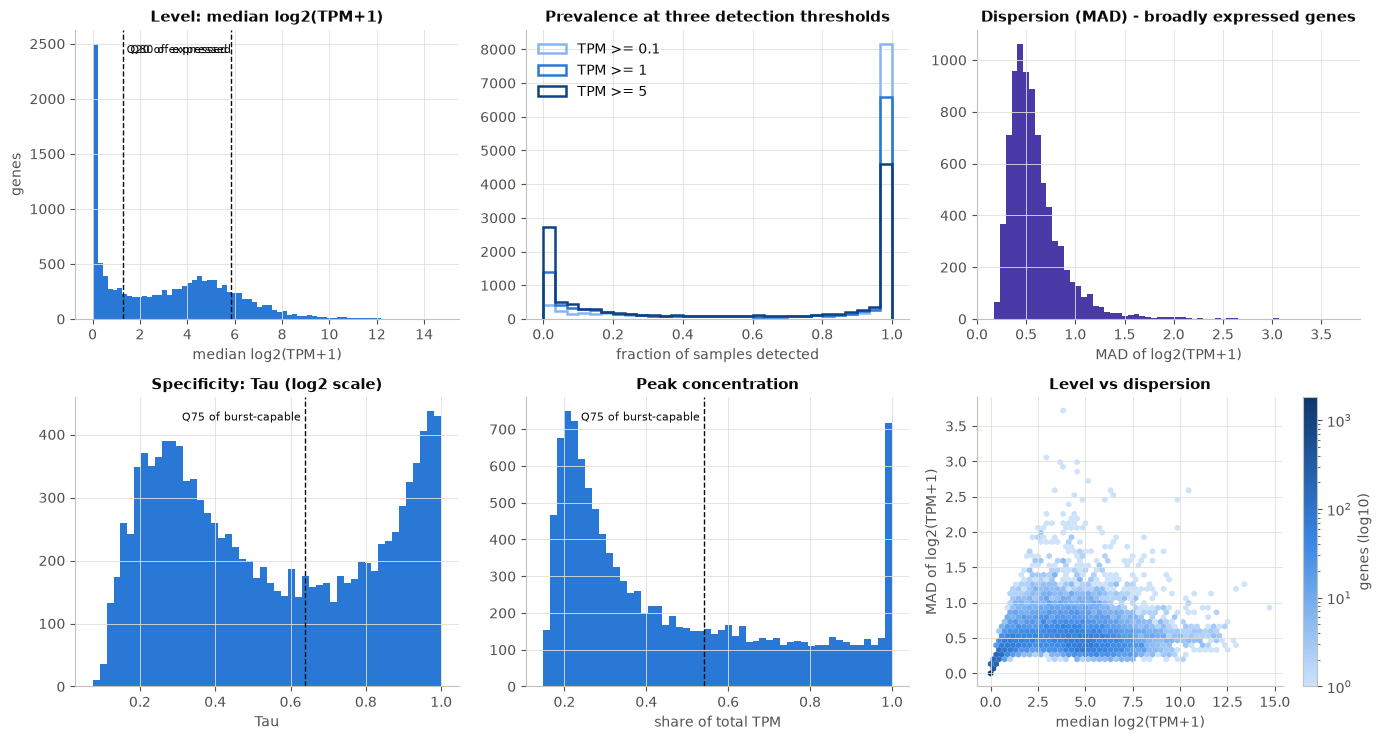

**Answer.** Expression level is bimodal (a silent/low mode and an expressed mode), prevalence is U-shaped (most genes are either detected almost everywhere or almost nowhere), and Tau spans the whole 0–1 range. Among the 8,196 broadly expressed genes (median TPM ≥ 1) a 2-component mixture on MAD fits better than 1 (BIC 2,584 → -812) and assigns **21%** of genes to a high-dispersion component (MAD ≈ 0.94 vs ≈ 0.50 for the stable one). The histogram is a right-skewed single peak with a long tail, so the mixture is best read as a description of that tail (supporting a ~20% tail cut as a convention), not as proof of two discrete populations. Dispersion also rises with level up to a plateau, so it must be compared **within level tiers**.

In [6]:
th = derive_thresholds(metrics)   # computed here only to draw the candidate cut-offs on the distributions
broad = metrics["median_TPM"] >= 1.0

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
ax = axes[0, 0]
ax.hist(metrics["median_logTPM"], bins=70, color="#2a78d6")
for v, lab in ((th.level_low, "Q20 of expressed"), (th.level_high, "Q80 of expressed")):
    ax.axvline(v, color=INK, lw=1, ls="--"); ax.text(v, ax.get_ylim()[1] * 0.92, f" {lab}", fontsize=8, color=INK, ha="right" if v == th.level_high else "left")
ax.set_title("Level: median log2(TPM+1)"); ax.set_xlabel("median log2(TPM+1)"); ax.set_ylabel("genes")

ax = axes[0, 1]
for col, c in zip(["prevalence_TPM_0.1", "prevalence_TPM_1", "prevalence_TPM_5"], ["#86b6ef", "#2a78d6", "#104281"]):
    ax.hist(metrics[col], bins=30, histtype="step", lw=1.8, color=c, label=col.replace("prevalence_", "TPM >= ").replace("TPM_", ""))
ax.set_title("Prevalence at three detection thresholds"); ax.set_xlabel("fraction of samples detected"); ax.legend(frameon=False)

ax = axes[0, 2]
ax.hist(metrics.loc[broad, "MAD_logTPM"], bins=60, color="#4a3aa7")
ax.set_title("Dispersion (MAD) - broadly expressed genes"); ax.set_xlabel("MAD of log2(TPM+1)")

ax = axes[1, 0]
ax.hist(metrics["Tau"].dropna(), bins=50, color="#2a78d6")
ax.axvline(th.tau_specific, color=INK, lw=1, ls="--"); ax.text(th.tau_specific, ax.get_ylim()[1] * 0.92, "Q75 of burst-capable ", fontsize=8, ha="right")
ax.set_title("Specificity: Tau (log2 scale)"); ax.set_xlabel("Tau")

ax = axes[1, 1]
ax.hist(metrics["peak_share_top10pct"].dropna(), bins=50, color="#2a78d6")
ax.axvline(th.peak_specific, color=INK, lw=1, ls="--"); ax.text(th.peak_specific, ax.get_ylim()[1] * 0.92, "Q75 of burst-capable ", fontsize=8, ha="right")
ax.set_title("Peak concentration"); ax.set_xlabel("share of total TPM")

ax = axes[1, 2]
hb = ax.hexbin(metrics["median_logTPM"], metrics["MAD_logTPM"], gridsize=50, cmap=BLUE, mincnt=1, bins="log", linewidths=0)
ax.set_title("Level vs dispersion")
ax.set_xlabel("median log2(TPM+1)"); ax.set_ylabel("MAD of log2(TPM+1)")
fig.colorbar(hb, ax=ax, label="genes (log10)")
fig.tight_layout(); save_fig(fig, "rank_distributions.png"); plt.show()

# Natural break in dispersion among broadly expressed genes: 1 vs 2 mixture components.
x_mad = metrics.loc[broad, "MAD_logTPM"].to_numpy().reshape(-1, 1)
g1 = GaussianMixture(1, random_state=RNG_SEED).fit(x_mad)
g2 = GaussianMixture(2, n_init=5, random_state=RNG_SEED).fit(x_mad)
hi_mode = int(np.argmax(g2.means_.ravel()))
display(Markdown(
    f"**Answer.** Expression level is bimodal (a silent/low mode and an expressed mode), prevalence is U-shaped (most genes are either "
    f"detected almost everywhere or almost nowhere), and Tau spans the whole 0–1 range. Among the {int(broad.sum()):,} broadly expressed genes "
    f"(median TPM ≥ 1) a 2-component mixture on MAD fits {'better' if g2.bic(x_mad) < g1.bic(x_mad) else 'no better'} than 1 "
    f"(BIC {g1.bic(x_mad):,.0f} → {g2.bic(x_mad):,.0f}) and assigns **{g2.weights_[hi_mode]:.0%}** of genes to a high-dispersion component "
    f"(MAD ≈ {g2.means_.ravel()[hi_mode]:.2f} vs ≈ {g2.means_.ravel()[1 - hi_mode]:.2f} for the stable one). The histogram is a right-skewed single peak with a long tail, "
    f"so the mixture is best read as a description of that tail (supporting a ~20% tail cut as a convention), not as proof of two discrete populations. "
    f"Dispersion also rises with level up to a plateau, so it must be compared **within level tiers**."
))


**Conclusion.** The data themselves suggest where the cut-offs should fall: the level distribution is
split by the expressed/silent gap (so level quantiles are taken over *expressed* genes only, otherwise "low"
would just mean "silent"); dispersion has a long high tail whose mixture weight is close to the 0.80 tail
quantile used in the class rules (a convention supported, not proven, by the data); and log-scale dispersion is mechanically compressed at low level, which is why
dispersion and Tau are ranked against genes of the *same level tier* rather than globally.


## 4. Do natural gene groups exist? (unsupervised exploration)

**Question.** Before fixing any rule, do genes form natural groups in the feature space
(median log-level, prevalence, MAD, IQR, Tau, log2 P90/median) — and do the six expected archetypes
(constitutive-high/core/low, broad-variable, context-specific, rare/silent) appear on their own?
We use a Gaussian Mixture (BIC scan), HDBSCAN (density-based, no k) and Ward hierarchical clustering.
Clustering is used here as **evidence about the structure**, not as the final classifier.


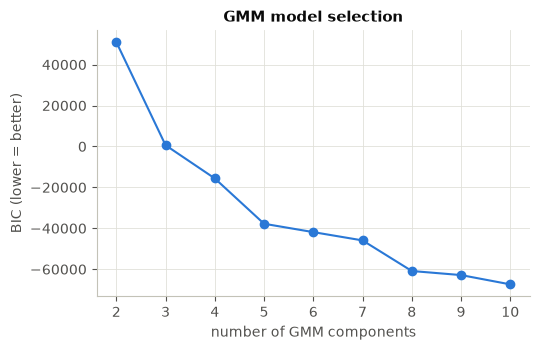

,n_genes,median_logTPM,prevalence_TPM_1,MAD_logTPM,IQR_logTPM,Tau,log2_P90_to_median
cluster,,,,,,,
0,2089,0.00,0.02,0.00,0.00,0.96,0.23
1,1743,3.82,0.99,0.58,1.29,0.41,1.45
2,894,2.86,0.93,0.90,2.01,0.57,2.31
3,4569,5.23,1.00,0.47,0.97,0.27,0.92
4,1012,0.54,0.32,0.37,1.09,0.82,2.51
5,1771,0.79,0.36,0.33,0.71,0.76,1.05


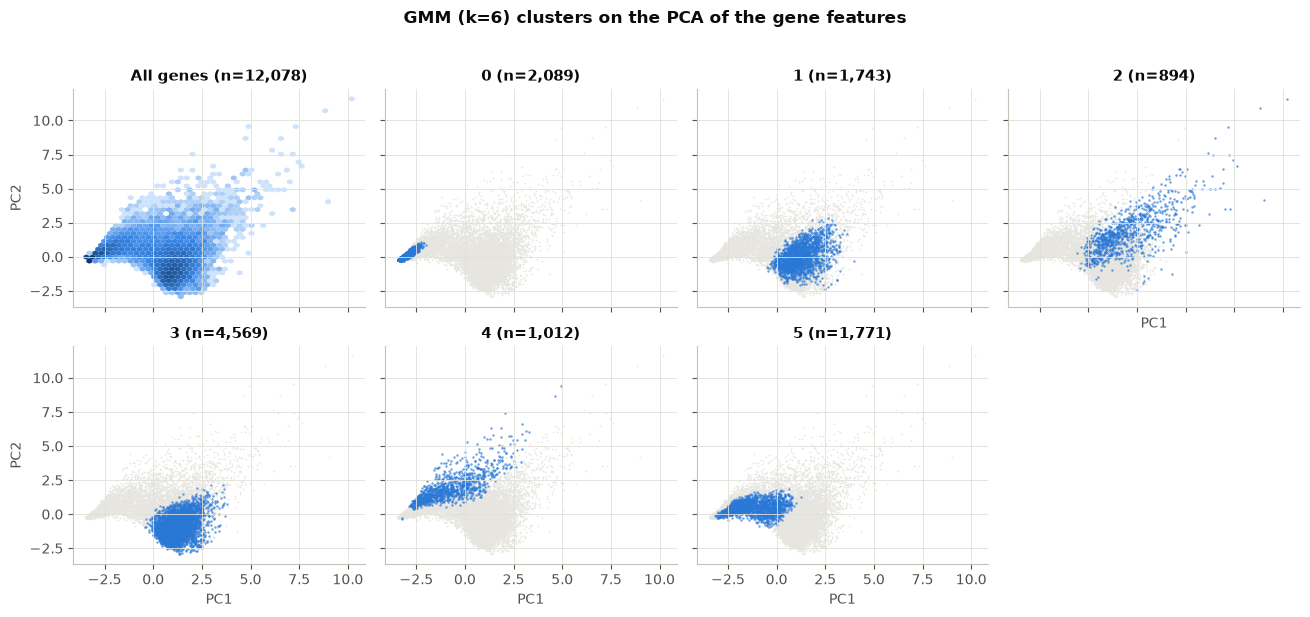

**Answer.** BIC keeps decreasing up to the largest k tested (10) — the data do not show a sharp elbow, i.e. gene behavior is better described as a **continuum with density concentrations** than as discrete groups. HDBSCAN finds 2 dense cluster(s) and labels 41% of genes as diffuse/noise; Ward (k=6) agrees with the GMM on a 4,000-gene subsample at ARI = 0.51. PC1/PC2 explain 90% of feature variance. The six-component GMM centroids above show which expected archetypes emerge unsupervised (silent, stable-high, stable-mid, variable, spiky/context-specific, low/sparse).

In [7]:
feat = pd.DataFrame({
    "median_logTPM": metrics["median_logTPM"], "prevalence_TPM_1": metrics["prevalence_TPM_1"],
    "MAD_logTPM": metrics["MAD_logTPM"], "IQR_logTPM": metrics["IQR_logTPM"],
    "Tau": metrics["Tau"].fillna(1.0),   # undefined only for never-expressed genes: no evidence of breadth
    "log2_P90_to_median": np.log2(metrics["P90_to_median_ratio"]),
})
X_std = StandardScaler().fit_transform(feat)

bic = pd.Series({k: GaussianMixture(k, n_init=3, random_state=RNG_SEED).fit(X_std).bic(X_std) for k in range(2, 11)}, name="BIC")
gmm6 = GaussianMixture(6, n_init=5, random_state=RNG_SEED).fit(X_std)
gmm_labels = pd.Series(gmm6.predict(X_std), index=feat.index, name="gmm6")

hdb = HDBSCAN(min_cluster_size=max(50, int(0.01 * len(X_std)))).fit(X_std)
hdb_labels = pd.Series(hdb.labels_, index=feat.index)
n_hdb, noise_hdb = int(hdb_labels.max() + 1), float((hdb_labels == -1).mean())

sub = rng.choice(len(X_std), size=min(4000, len(X_std)), replace=False)
ward = AgglomerativeClustering(n_clusters=6, linkage="ward").fit_predict(X_std[sub])
ari_ward_gmm = adjusted_rand_score(ward, gmm_labels.iloc[sub])

pca = PCA(n_components=2, random_state=RNG_SEED).fit(X_std)
pcs = pd.DataFrame(pca.transform(X_std), index=feat.index, columns=["PC1", "PC2"])

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(bic.index, bic.values, marker="o", color="#2a78d6")
ax.set_xlabel("number of GMM components"); ax.set_ylabel("BIC (lower = better)"); ax.set_title("GMM model selection")
fig.tight_layout(); save_fig(fig, "rank_unsupervised_bic.png"); plt.show()

centroids = feat.assign(cluster=gmm_labels).groupby("cluster").agg(
    n_genes=("Tau", "size"), median_logTPM=("median_logTPM", "median"), prevalence_TPM_1=("prevalence_TPM_1", "median"),
    MAD_logTPM=("MAD_logTPM", "median"), IQR_logTPM=("IQR_logTPM", "median"), Tau=("Tau", "median"),
    log2_P90_to_median=("log2_P90_to_median", "median"),
).round(2)
display(centroids)
facet_highlight(pcs, gmm_labels, list(range(6)), "PC1", "PC2", "GMM (k=6) clusters on the PCA of the gene features",
                "rank_unsupervised_gmm_pca.png", ncols=4)

drop_last = (bic.iloc[-2] - bic.iloc[-1]) / abs(bic.iloc[0] - bic.iloc[1]) if bic.iloc[0] != bic.iloc[1] else np.nan
display(Markdown(
    f"**Answer.** BIC {'keeps decreasing up to the largest k tested (' + str(int(bic.index[-1])) + ')' if bic.idxmin() == bic.index[-1] else 'bottoms out at k = ' + str(int(bic.idxmin()))} — "
    f"the data do not show a sharp elbow, i.e. gene behavior is better described as a **continuum with density concentrations** than as discrete groups. "
    f"HDBSCAN finds {n_hdb} dense cluster(s) and labels {noise_hdb:.0%} of genes as diffuse/noise; Ward (k=6) agrees with the GMM on a "
    f"{len(sub):,}-gene subsample at ARI = {ari_ward_gmm:.2f}. PC1/PC2 explain {pca.explained_variance_ratio_.sum():.0%} of feature variance. "
    f"The six-component GMM centroids above show which expected archetypes emerge unsupervised (silent, stable-high, stable-mid, variable, "
    f"spiky/context-specific, low/sparse)."
))


**Conclusion.** The archetypes the project expects are visible as *concentrations* of genes but not as cleanly
separated clusters, which is exactly why the final classes are rule-based with transparent, quantile-derived
thresholds rather than a clustering output: a clustering would impose hard borders where the data show a
continuum, and its borders would move with every added study. The unsupervised result is kept as an
independent check on the rules (Section 5 compares the two) and the continuous scores (Section 6) preserve
the gradient the classes necessarily coarsen.


## 5. Quantile-derived thresholds and the expression classes

**Question.** Can the six requested classes (Constitutive High / Core / Low, Broad Variable, Context-Specific,
Rare/Silent) be assigned with thresholds derived from the atlas' own distributions — no absolute TPM cut-offs —
and how do they compare with the unsupervised structure from Section 4?

*Rules* (applied in this order; every gene gets exactly one class — full definitions in
`aoryzae_atlas/rank/classes.py`):

1. **Context-Specific** — reaches, in at least one sample, the *median level of the expressed transcriptome*
   (so a sub-TPM blip is not a "burst"), and both Tau and peak concentration are in the top quartile of such genes.
2. **Rare/Silent** — not detected in the typical sample, no strong bursts.
3. **Constitutive High / Core / Low** — detected in (nearly) every sample, outside the high-dispersion and
   high-Tau tails *of its level tier*; High/Core/Low = top 20% / middle / bottom 20% of expressed genes by
   median level.
4. **Broad Variable** — expressed in the typical sample, inside the high-dispersion tail of its tier, not
   concentrated in few samples.
5. **Intermediate** — the honest remainder of a continuum (e.g. broad genes with high Tau but no burst).


,threshold,value,meaning
0,expressed genes (median TPM >= 0.1),9810.0000,reference population for level quantiles
1,level_low (Q20 of expressed),1.2670,median log2(TPM+1); = 1.41 TPM; Low/Core boundary
2,level_high (Q80 of expressed),5.8400,median log2(TPM+1); = 56.3 TPM; Core/High boun...
3,burst floor,14.5790,TPM at the Q50 level of expressed genes: to co...
4,burst-capable genes,9417.0000,reference population for the specificity quant...
5,Tau cut (Q75 of burst-capable),0.6380,Context-Specific needs Tau >= this
6,peak-share cut (Q75 of burst-capable),0.5410,Context-Specific needs peak share >= this
7,broad-prevalence cut (Q25 of expressed),0.9934,fraction of samples with TPM >= 0.1 needed to ...
8,"tail quantile (dispersion, Tau)",0.8000,within-tier percentile above which dispersion/...


,n_genes,median_TPM,median_logTPM,prevalence_TPM_0.1,prevalence_TPM_1,MAD_logTPM,IQR_logTPM,Tau,peak_share_top10pct
expression_class,,,,,,,,,
Constitutive High,1363,121.088,6.932,1.000,1.000,0.437,0.907,0.187,0.205
Constitutive Core,3573,20.421,4.421,1.000,1.000,0.475,0.980,0.325,0.242
Constitutive Low,90,1.091,1.064,1.000,0.543,0.326,0.711,0.664,0.365
Broad Variable,1642,18.175,4.261,1.000,0.993,0.870,1.839,0.444,0.377
Context-Specific,1955,0.386,0.471,0.808,0.272,0.308,0.801,0.848,0.812
Rare/Silent,1708,0.000,0.000,0.126,0.013,0.000,0.000,0.955,0.865
Intermediate,1747,1.920,1.546,0.987,0.801,0.396,0.841,0.639,0.415


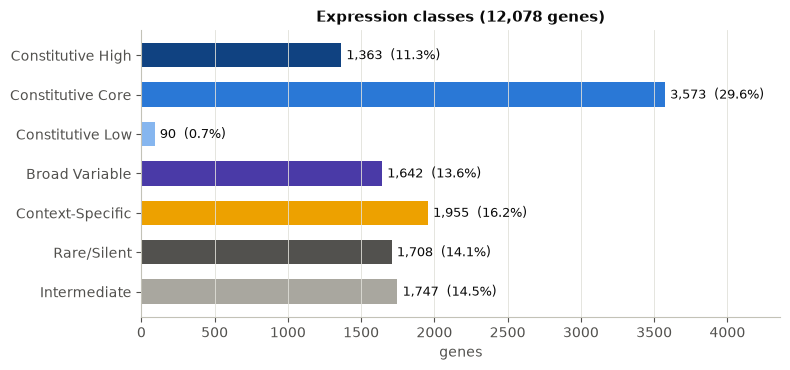

,Constitutive High,Constitutive Core,Constitutive Low,Broad Variable,Context-Specific,Rare/Silent,Intermediate,dominant class,share of the cluster in its dominant class
GMM cluster,,,,,,,,,
0,0,0,0,0,426,1625,38,Rare/Silent,0.78
1,97,935,0,430,35,0,246,Constitutive Core,0.54
2,2,71,0,466,204,0,151,Broad Variable,0.52
3,1264,2507,0,520,9,0,269,Constitutive Core,0.55
4,0,0,7,80,840,36,49,Context-Specific,0.83
5,0,60,83,146,441,47,994,Intermediate,0.56


In [8]:
params = ClassParams()
th = derive_thresholds(metrics, params)
classes = assign_classes(metrics, params)
tiers = level_tiers(metrics, params)

th_table = pd.DataFrame([
    ("expressed genes (median TPM >= 0.1)", th.n_expressed_genes, "reference population for level quantiles"),
    ("level_low  (Q20 of expressed)", round(th.level_low, 3), f"median log2(TPM+1); = {2 ** th.level_low - 1:.2f} TPM; Low/Core boundary"),
    ("level_high (Q80 of expressed)", round(th.level_high, 3), f"median log2(TPM+1); = {2 ** th.level_high - 1:.1f} TPM; Core/High boundary"),
    ("burst floor", round(th.floor_tpm, 3), f"TPM at the Q{int(params.burst_quantile * 100)} level of expressed genes: to count as context-specific a gene must reach at least this in one sample (become a normally expressed gene somewhere)"),
    ("burst-capable genes", th.n_burst_capable_genes, "reference population for the specificity quantiles"),
    ("Tau cut (Q75 of burst-capable)", round(th.tau_specific, 3), "Context-Specific needs Tau >= this"),
    ("peak-share cut (Q75 of burst-capable)", round(th.peak_specific, 3), "Context-Specific needs peak share >= this"),
    ("broad-prevalence cut (Q25 of expressed)", round(th.prevalence_broad, 4), "fraction of samples with TPM >= 0.1 needed to be called 'detected everywhere'"),
    ("tail quantile (dispersion, Tau)", params.tail_quantile, "within-tier percentile above which dispersion/Tau count as high"),
], columns=["threshold", "value", "meaning"])
display(th_table)
th_table.to_csv(EXPRESSION_RANK_THRESHOLDS_FILE, sep="\t", index=False)

counts = classes.value_counts().reindex(CLASS_ORDER)
profile = metrics.join(classes.rename("expression_class")).groupby("expression_class", observed=True)[
    ["median_TPM", "median_logTPM", "prevalence_TPM_0.1", "prevalence_TPM_1", "MAD_logTPM", "IQR_logTPM", "Tau", "peak_share_top10pct"]
].median().reindex(CLASS_ORDER).round(3)
profile.insert(0, "n_genes", counts)
display(profile)

fig, ax = plt.subplots(figsize=(8, 3.8))
ypos = np.arange(len(CLASS_ORDER))[::-1]
ax.barh(ypos, counts.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER], height=0.62)
for yv, c, n in zip(ypos, CLASS_ORDER, counts.values):
    ax.text(n + counts.max() * 0.01, yv, f"{n:,}  ({n / counts.sum():.1%})", va="center", fontsize=9, color=INK)
ax.set_yticks(ypos); ax.set_yticklabels(CLASS_ORDER); ax.set_xlim(0, counts.max() * 1.22)
ax.set_xlabel("genes"); ax.set_title(f"Expression classes ({int(counts.sum()):,} genes)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save_fig(fig, "rank_class_counts.png"); plt.show()

ari_rules_gmm = adjusted_rand_score(classes.astype(str), gmm_labels.reindex(classes.index))
cross = pd.crosstab(gmm_labels.reindex(classes.index).rename("GMM cluster"), classes.rename("expression_class")).reindex(columns=CLASS_ORDER)
purity = (cross.max(axis=1) / cross.sum(axis=1)).round(2).rename("share of the cluster in its dominant class")
display(pd.concat([cross, cross.idxmax(axis=1).rename("dominant class"), purity], axis=1))


In [9]:
major = counts.sort_values(ascending=False)
agreement_word = "strongly" if ari_rules_gmm >= 0.6 else ("moderately" if ari_rules_gmm >= 0.3 else "only weakly")
display(Markdown(
    f"**Answer.** All {int(counts.sum()):,} genes receive one class. The largest are **{major.index[0]}** ({major.iloc[0]:,}, {major.iloc[0] / counts.sum():.0%}) and "
    f"**{major.index[1]}** ({major.iloc[1]:,}); Constitutive genes together are {int(counts[[c for c in CLASS_ORDER if c.startswith('Constitutive')]].sum()):,} "
    f"({counts[[c for c in CLASS_ORDER if c.startswith('Constitutive')]].sum() / counts.sum():.0%}), Broad Variable {int(counts['Broad Variable']):,}, "
    f"Context-Specific {int(counts['Context-Specific']):,}, Rare/Silent {int(counts['Rare/Silent']):,}, and the Intermediate remainder is "
    f"{counts['Intermediate'] / counts.sum():.0%}. The class profiles are monotone where they should be (level and prevalence fall from Constitutive High to Rare/Silent; "
    f"dispersion peaks in Broad Variable; Tau and peak concentration peak in Context-Specific/Rare). Against the unsupervised GMM-6 partition the rules agree "
    f"**{agreement_word}** (ARI = {ari_rules_gmm:.2f}); each GMM cluster is dominated by one rule class at purity {purity.min():.2f}–{purity.max():.2f}: "
    + "; ".join(f"cluster {k} -> {cross.idxmax(axis=1)[k]} ({purity[k]:.0%})" for k in cross.index) + "."
))


**Answer.** All 12,078 genes receive one class. The largest are **Constitutive Core** (3,573, 30%) and **Context-Specific** (1,955); Constitutive genes together are 5,026 (42%), Broad Variable 1,642, Context-Specific 1,955, Rare/Silent 1,708, and the Intermediate remainder is 14%. The class profiles are monotone where they should be (level and prevalence fall from Constitutive High to Rare/Silent; dispersion peaks in Broad Variable; Tau and peak concentration peak in Context-Specific/Rare). Against the unsupervised GMM-6 partition the rules agree **moderately** (ARI = 0.34); each GMM cluster is dominated by one rule class at purity 0.52–0.83: cluster 0 -> Rare/Silent (78%); cluster 1 -> Constitutive Core (54%); cluster 2 -> Broad Variable (52%); cluster 3 -> Constitutive Core (55%); cluster 4 -> Context-Specific (83%); cluster 5 -> Intermediate (56%).

**Conclusion.** The six requested classes can be recovered with thresholds that are all quantiles of the
atlas' own distributions (printed above and saved to `gene_expression_rank_thresholds.tsv`). They are only
*partly* aligned with a six-component mixture (see the ARI above) — expected, because the mixture and the rules
cut a continuum in different places (the mixture, for instance, keeps a large stable cluster that the rules split
into High/Core tiers by level) — but each mixture cluster is dominated by a coherent rule class, so the two views
tell the same story at the level of families. Two properties of this design must be kept in mind when using the
classes: (1) they are **relative** — the Broad Variable and "high-Tau" tails are cut at a within-tier
quantile, so a fixed share of each tier is always flagged at the tails whatever the data look like (here the
cut is supported by the mixture result in Section 3, but it is a convention, not a measurement);
(2) a continuum is coarsened — the **Intermediate** class is reported explicitly rather than forced into a
neighbour. Section 6 keeps the full gradient as continuous scores, and Section 9 quantifies how sensitive
each class is to the quantile choices.


## 6. Continuous scores and global rank

**Question.** Beyond the categories, can every gene be ordered on *separate* axes — level, stability,
specificity, prevalence — without collapsing "high" and "stable" into one number?

Scores are percentile ranks in (0, 1]. `expression_stability_score` is the geometric mean of the prevalence
score and the low-MAD, low-IQR and low-Tau ranks (a gene is stable only if all four agree, so a silent gene —
zero dispersion, zero prevalence — cannot score as stable). `global_expression_rank` orders genes by
`constitutive_score` (geometric mean of level, stability and prevalence); the other orderings
(most expressed / stable / variable / specific / rarest) are separate columns.


,expression_level_score,expression_stability_score,expression_specificity_score,expression_prevalence_score
expression_level_score,1.00,0.52,-0.86,0.96
expression_stability_score,0.52,1.00,-0.68,0.59
expression_specificity_score,-0.86,-0.68,1.00,-0.86
expression_prevalence_score,0.96,0.59,-0.86,1.00


**Top 8 - most constitutively expressed (global_expression_rank)**

,gene_symbol,description,expression_class,median_TPM,prevalence_TPM_1,MAD_logTPM,Tau
canonical_gene_id,,,,,,,
AO090102000638,,Ortholog(s) have GTPase activity and role in E...,Constitutive High,629.75,1.0,0.22,0.12
AO090701000168,,Ortholog(s) have proton-transporting ATP synth...,Constitutive High,1121.94,1.0,0.22,0.10
AO090005000604,,Ortholog(s) have proton-transporting ATP synth...,Constitutive High,902.67,1.0,0.23,0.08
AO090113000080,,"Ortholog(s) have chaperone binding activity, r...",Constitutive High,858.35,1.0,0.24,0.09
AO090701001094,,"Ortholog(s) have DNA binding, bending, sequenc...",Constitutive High,1210.44,1.0,0.26,0.09
AO090020000122,,Ortholog(s) have ribosomal small subunit bindi...,Constitutive High,693.50,1.0,0.24,0.14
AO090120000091,,"Ortholog(s) have fungal-type vacuole membrane,...",Constitutive High,270.37,1.0,0.21,0.10
AO090003001227,,"Calmodulin, intracellular Ca2+ receptor, predi...",Constitutive High,627.12,1.0,0.27,0.12


**Top 8 - most highly expressed (rank_most_expressed)**

,gene_symbol,description,expression_class,median_TPM,prevalence_TPM_1,MAD_logTPM,Tau
canonical_gene_id,,,,,,,
AO090003000090,,Thiamine biosynthetic enzyme,Broad Variable,26934.72,1.00,0.96,0.15
AO090005000029,,Extracellular lipase (cutinase) with role in l...,Broad Variable,10513.74,0.95,1.29,0.38
AO090003001322,,Predicted glyceraldehyde-3-phosphate dehydroge...,Constitutive High,7677.41,1.00,0.48,0.11
AO090701001051,,protein of unknown function,Broad Variable,7308.30,0.99,1.21,0.29
AO090120000080,,Translation elongation factor EF-1-alpha,Constitutive High,7216.67,1.00,0.39,0.13
AO090011000414,,Ortholog(s) have glyceraldehyde-3-phosphate de...,Broad Variable,6451.40,0.99,0.73,0.15
AO090009000405,,Ortholog(s) have ATP:ADP antiporter activity a...,Constitutive High,6139.42,1.00,0.35,0.09
AO090011000954,,Ortholog(s) have cytosol localization,Constitutive High,5387.42,1.00,0.70,0.11


**Top 8 - most stable (rank_most_stable)**

... (3 outputs left out)

**Top 8 - most specific (rank_most_specific)**

,gene_symbol,description,expression_class,median_TPM,prevalence_TPM_1,MAD_logTPM,Tau
canonical_gene_id,,,,,,,
AO090701000873,,protein of unknown function,Rare/Silent,0.0,0.01,0.0,1.0
AO090124000038,,Ortholog of Aspergillus flavus NRRL 3357 : AFL...,Rare/Silent,0.0,0.01,0.0,1.0
AO090113000069,,protein of unknown function,Rare/Silent,0.0,0.01,0.0,1.0
AO090020000245,,protein of unknown function,Rare/Silent,0.0,0.01,0.0,1.0
AO090010000697,,protein of unknown function,Rare/Silent,0.0,0.01,0.0,1.0
AO090002000010,,Ortholog(s) have proton-transporting ATP synth...,Rare/Silent,0.0,0.01,0.0,1.0
AO090001000318,,protein of unknown function,Rare/Silent,0.0,0.01,0.0,1.0
AO090003000739,,protein of unknown function,Rare/Silent,0.0,0.01,0.0,1.0


**Top 8 - rarest (rank_rarest)**

,gene_symbol,description,expression_class,median_TPM,prevalence_TPM_1,MAD_logTPM,Tau
canonical_gene_id,,,,,,,
AO090001000056,,Has domain(s) with predicted methyltransferase...,Rare/Silent,0.0,0.0,0.0,NaN
AO090001000080,,Has domain(s) with predicted catalytic activit...,Rare/Silent,0.0,0.0,0.0,0.99
AO090001000211,,protein of unknown function,Rare/Silent,0.0,0.0,0.0,NaN
AO090001000644,,"Has domain(s) with predicted DNA binding, nucl...",Rare/Silent,0.0,0.0,0.0,1.00
AO090003001275,,protein of unknown function,Rare/Silent,0.0,0.0,0.0,NaN
AO090003001303,,Ortholog of Aspergillus flavus NRRL 3357 : AFL...,Rare/Silent,0.0,0.0,0.0,NaN
AO090003001518,,protein of unknown function,Rare/Silent,0.0,0.0,0.0,NaN
AO090005000245,,Ortholog of Aspergillus flavus NRRL 3357 : AFL...,Rare/Silent,0.0,0.0,0.0,NaN


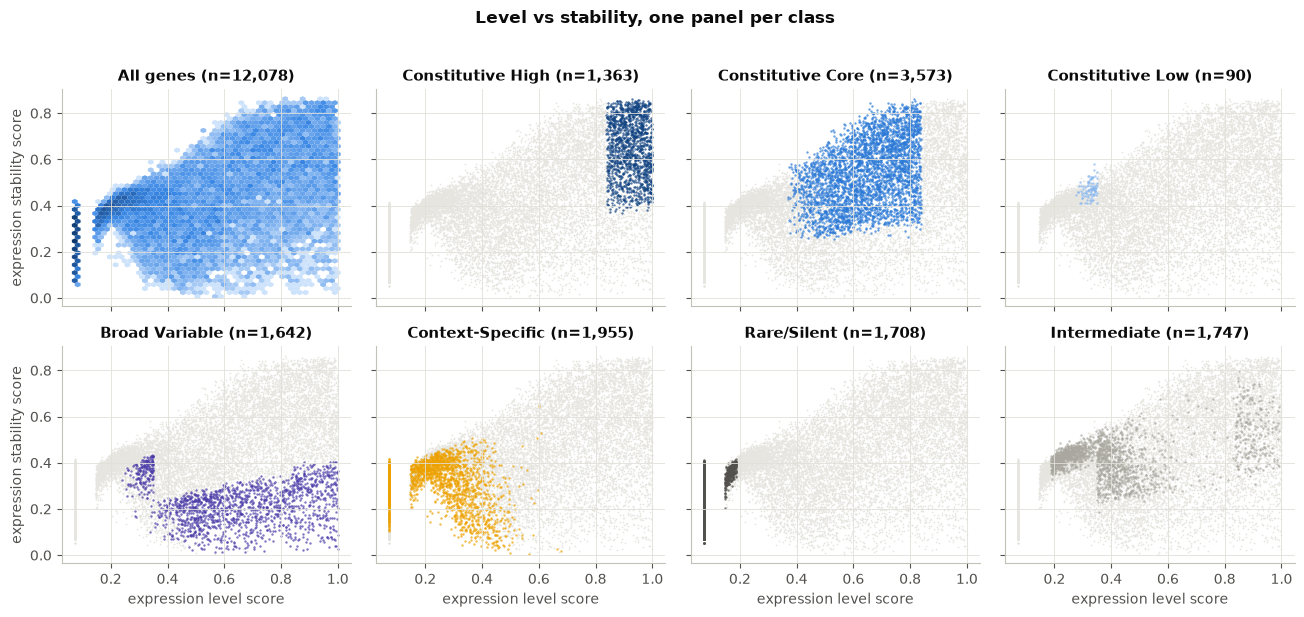

In [10]:
scores = compute_scores(metrics)
score_cols = ["expression_level_score", "expression_stability_score", "expression_specificity_score", "expression_prevalence_score"]
rho_scores = scores[score_cols].corr(method="spearman").round(2)
display(rho_scores)

annot = genes_tbl.reindex(metrics.index)
board = metrics.join(scores).join(classes.rename("expression_class")).join(annot[["gene_symbol", "description"]])
board["description"] = board["description"].fillna("").str.slice(0, 55)
board_cols = ["gene_symbol", "description", "expression_class", "median_TPM", "prevalence_TPM_1", "MAD_logTPM", "Tau"]
orderings = {
    "most constitutively expressed (global_expression_rank)": "global_expression_rank",
    "most highly expressed (rank_most_expressed)": "rank_most_expressed",
    "most stable (rank_most_stable)": "rank_most_stable",
    "most variable (rank_most_variable)": "rank_most_variable",
    "most specific (rank_most_specific)": "rank_most_specific",
    "rarest (rank_rarest)": "rank_rarest",
}
for title, col in orderings.items():
    display(Markdown(f"**Top 8 - {title}**"))
    display(board.sort_values(col).head(8)[board_cols].round(2))

facet_highlight(scores.rename(columns={"expression_level_score": "level", "expression_stability_score": "stability"})[["level", "stability"]],
                classes, CLASS_ORDER, "expression level score", "expression stability score",
                "Level vs stability, one panel per class", "rank_level_vs_stability.png", colors=CLASS_COLORS)


In [11]:
r_ls = rho_scores.loc["expression_level_score", "expression_stability_score"]
r_ss = rho_scores.loc["expression_specificity_score", "expression_stability_score"]
overlap = len(set(board.sort_values("rank_most_expressed").head(200).index) & set(board.sort_values("global_expression_rank").head(200).index))
display(Markdown(
    f"**Answer.** Level and stability are only partly related (Spearman ρ = {r_ls:.2f}), while specificity and stability are strongly opposed "
    f"(ρ = {r_ss:.2f}). Of the 200 most highly expressed genes, {overlap} are also among the 200 most constitutively expressed - "
    f"so ordering by raw expression level and ordering by constitutive behavior are materially different lists (see the top-8 tables)."
))


**Answer.** Level and stability are only partly related (Spearman ρ = 0.52), while specificity and stability are strongly opposed (ρ = -0.68). Of the 200 most highly expressed genes, 29 are also among the 200 most constitutively expressed - so ordering by raw expression level and ordering by constitutive behavior are materially different lists (see the top-8 tables).

**Conclusion.** The two main axes are separable: high level does not imply stability, which is the case the design
brief warns about ("high TPM but extremely variable must not be called constitutive-high"). The rank columns give
six ready-made orderings, and `global_expression_rank` is explicitly *one* of them (the constitutive ordering),
never a hidden blend: every component score stays in the table so a different composite can be built later.


## 7. Expression landscape and PCA of genes

**Question.** Where do the classes sit in the standard 2-D views (level × dispersion, prevalence × Tau,
level × Tau) and in a PCA of the gene features — do they occupy distinct, interpretable regions?
(One panel per class, the class in color over all other genes in gray.)


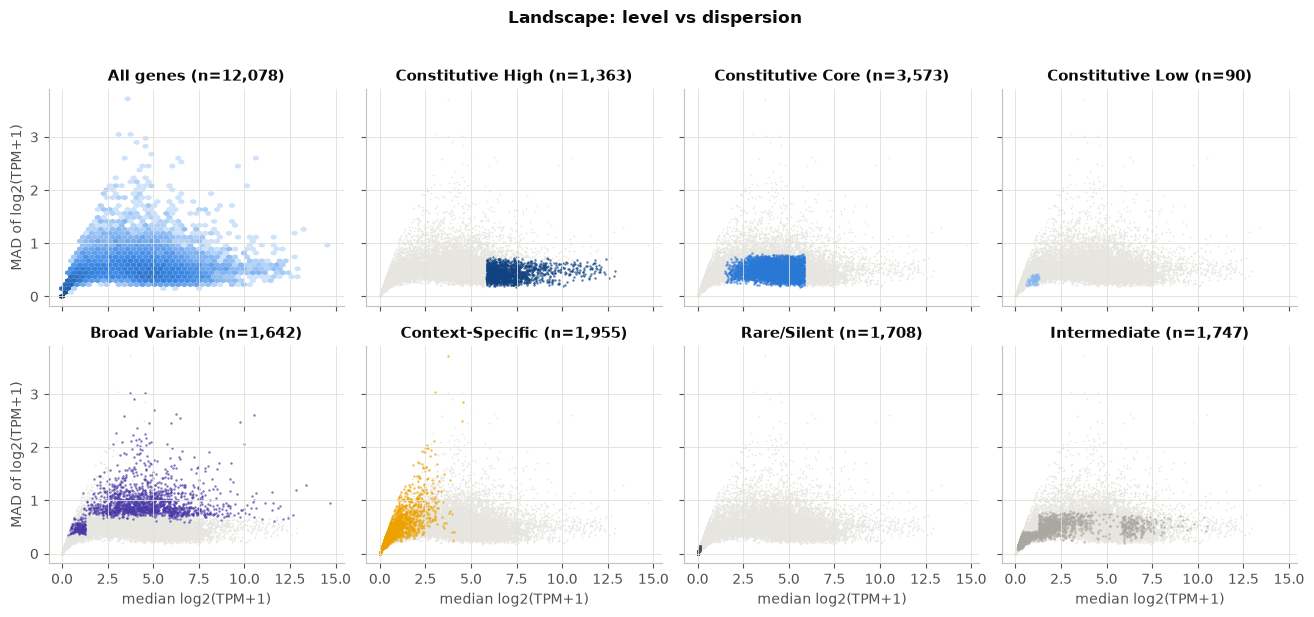

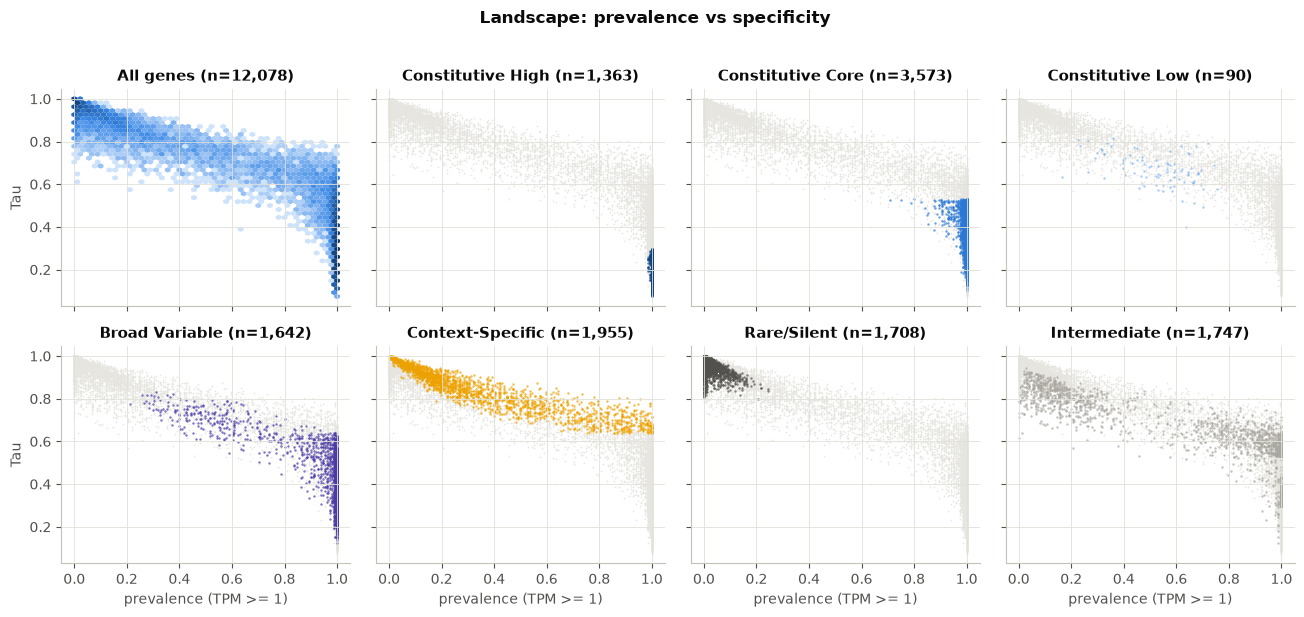

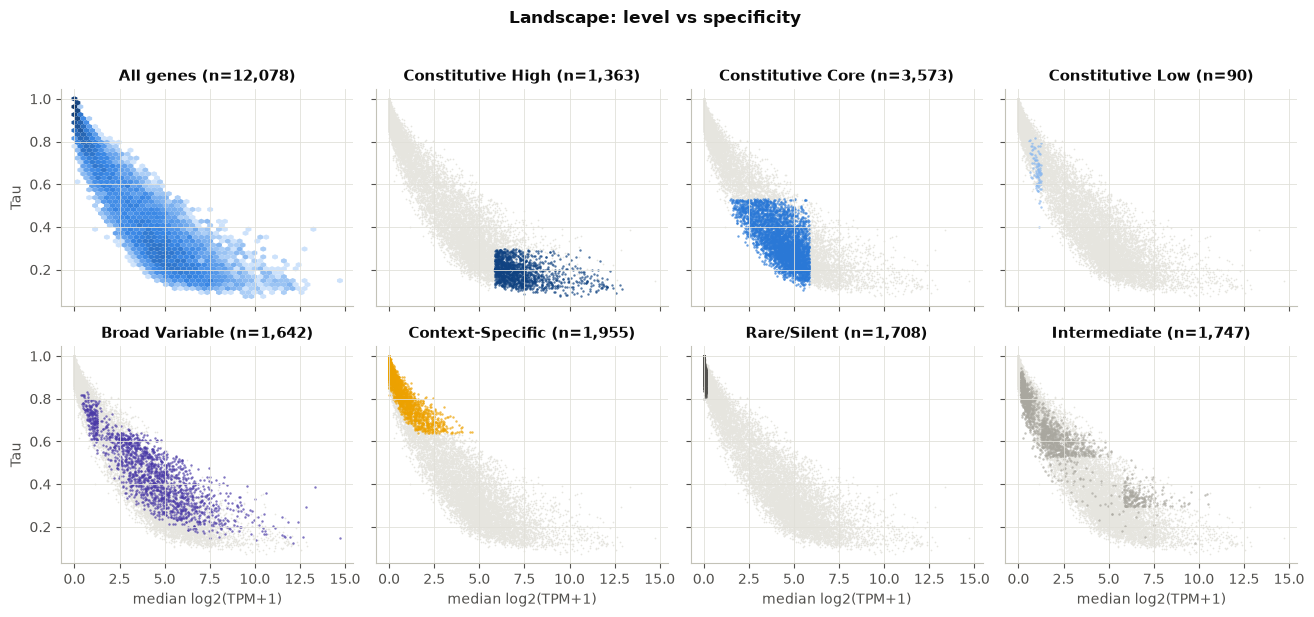

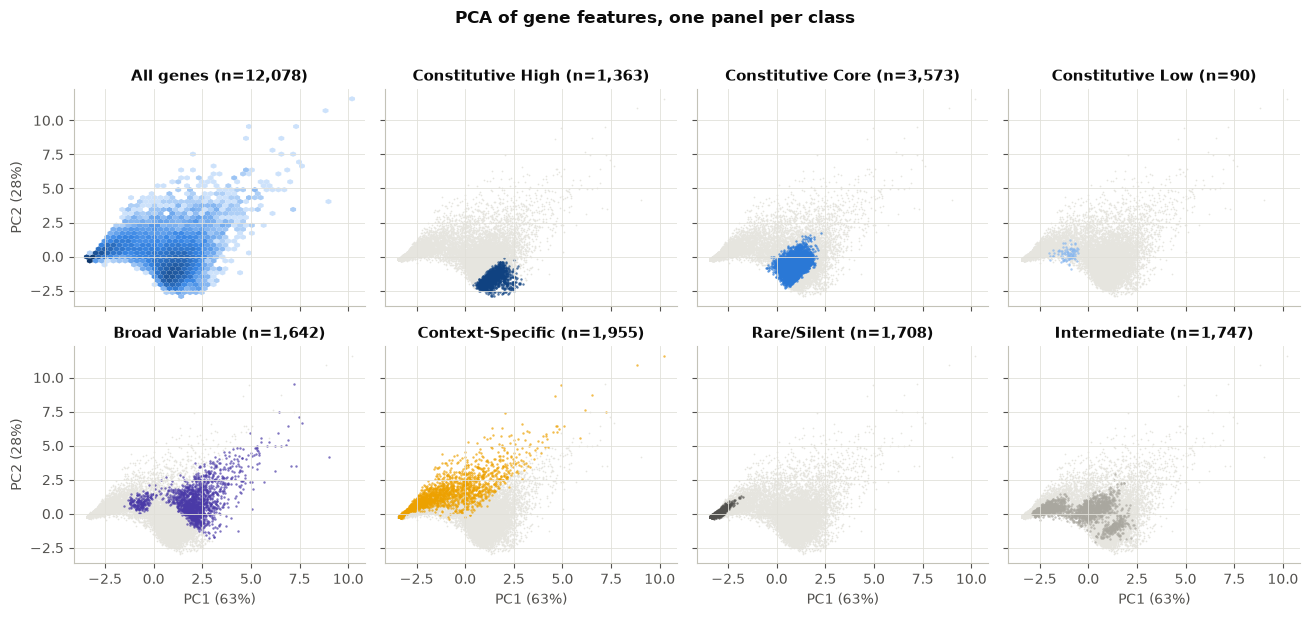

,PC1,PC2
median_logTPM,0.41,-0.39
prevalence_TPM_1,0.47,-0.22
MAD_logTPM,0.44,0.30
IQR_logTPM,0.42,0.40
Tau,-0.42,0.42
log2_P90_to_median,0.23,0.61


**Answer.** PC1 and PC2 together explain 90% of the feature variance; PC1 is dominated by prevalence_TPM_1 and PC2 by log2_P90_to_median (loadings above). In every view the classes occupy ordered, largely non-overlapping regions with Intermediate genes sitting between their neighbours; the mean distance between class medians in PC space is 2.7 (typical within-class SD 0.8).

In [12]:
landscape = metrics[["median_logTPM", "MAD_logTPM", "prevalence_TPM_1", "Tau"]].copy()
landscape["Tau"] = landscape["Tau"].fillna(1.0)
facet_highlight(landscape[["median_logTPM", "MAD_logTPM"]], classes, CLASS_ORDER, "median log2(TPM+1)", "MAD of log2(TPM+1)",
                "Landscape: level vs dispersion", "rank_landscape_level_vs_dispersion.png", colors=CLASS_COLORS)
facet_highlight(landscape[["prevalence_TPM_1", "Tau"]], classes, CLASS_ORDER, "prevalence (TPM >= 1)", "Tau",
                "Landscape: prevalence vs specificity", "rank_landscape_prevalence_vs_tau.png", colors=CLASS_COLORS)
facet_highlight(landscape[["median_logTPM", "Tau"]], classes, CLASS_ORDER, "median log2(TPM+1)", "Tau",
                "Landscape: level vs specificity", "rank_landscape_level_vs_tau.png", colors=CLASS_COLORS)
facet_highlight(pcs, classes, CLASS_ORDER, f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
                "PCA of gene features, one panel per class", "rank_pca.png", colors=CLASS_COLORS)

loadings = pd.DataFrame(pca.components_.T, index=feat.columns, columns=["PC1", "PC2"]).round(2)
display(loadings)
centroid_pc = pcs.join(classes.rename("expression_class")).groupby("expression_class", observed=True).median().reindex(CLASS_ORDER)
spread = pcs.join(classes.rename("expression_class")).groupby("expression_class", observed=True).std().reindex(CLASS_ORDER)
sep = float(np.mean([np.linalg.norm(centroid_pc.loc[a] - centroid_pc.loc[b]) for i, a in enumerate(CLASS_ORDER) for b in CLASS_ORDER[i + 1:]]))
display(Markdown(
    f"**Answer.** PC1 and PC2 together explain {pca.explained_variance_ratio_.sum():.0%} of the feature variance; PC1 is dominated by "
    f"{loadings['PC1'].abs().idxmax()} and PC2 by {loadings['PC2'].abs().idxmax()} (loadings above). In every view the classes occupy ordered, "
    f"largely non-overlapping regions with Intermediate genes sitting between their neighbours; the mean distance between class medians in PC space is {sep:.1f} "
    f"(typical within-class SD {float(spread.mean().mean()):.1f})."
))


**Conclusion.** The classes are not an artifact of the rule thresholds alone: they map onto contiguous regions of
the level × dispersion, prevalence × Tau and PCA landscapes, with a continuous gradient between neighbouring
classes rather than hard gaps (consistent with Section 4). Level × dispersion shows the structure that justifies
within-tier comparison, and prevalence × Tau shows the Context-Specific and Rare/Silent classes separating from
the broad genes along the specificity axis.


## 8. Representative expression profiles per class

**Question.** Do the raw profiles of typical genes from each class look the way the class names promise —
flat-and-high, flat-and-low, noisy-but-broad, spiky, absent?

Representatives are the genes closest to each class' median in standardized feature space (typical, not
extreme). Columns are the independent samples ordered by study then strain; values are log2(TPM+1).


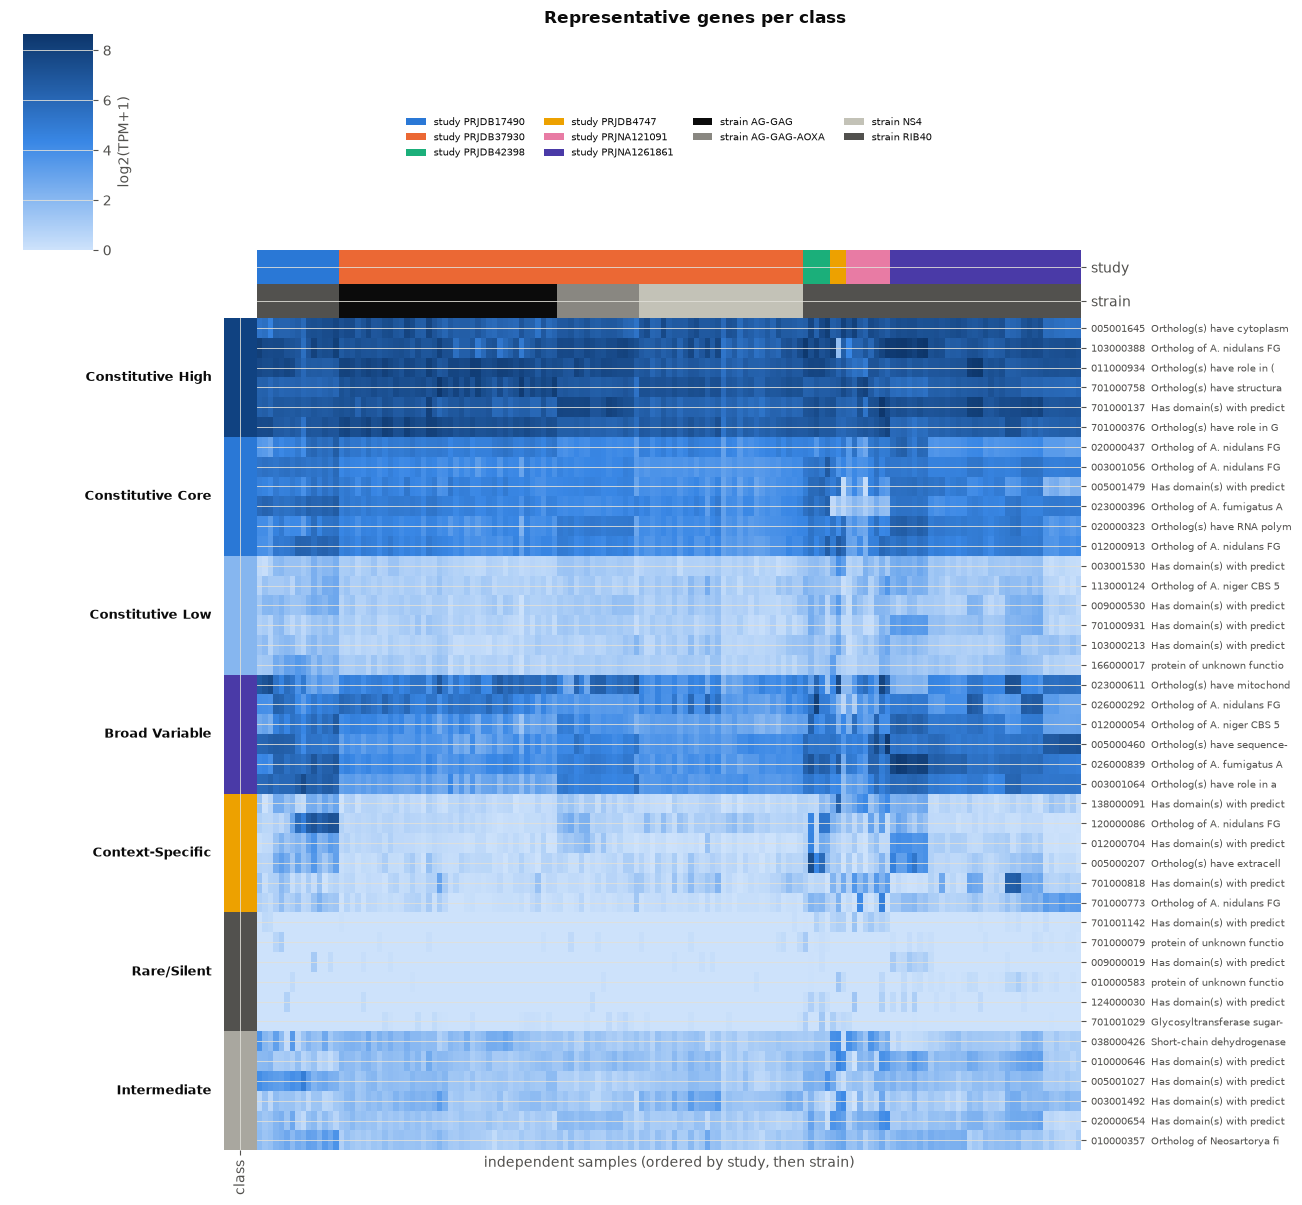

**Median of the representative genes' metrics (6 per class)**

,median_TPM,prevalence_TPM_1,MAD_logTPM,Tau,peak_share_top10pct
expression_class,,,,,
Constitutive High,112.09,1.00,0.44,0.19,0.21
Constitutive Core,20.71,1.00,0.48,0.33,0.25
Constitutive Low,1.07,0.56,0.33,0.66,0.35
Broad Variable,17.66,1.00,0.86,0.43,0.36
Context-Specific,0.49,0.27,0.31,0.84,0.74
Rare/Silent,0.00,0.01,0.00,0.96,0.89
Intermediate,1.74,0.80,0.41,0.63,0.35


In [13]:
X_df = pd.DataFrame(X_std, index=feat.index, columns=feat.columns)
reps = []
for cls in CLASS_ORDER:
    members = X_df.loc[classes.index[classes.astype(str) == cls]]
    center = members.median()
    reps += list((members - center).pow(2).sum(axis=1).nsmallest(6).index)
rep_classes = classes.loc[reps].astype(str)

col_order = unit_meta.sort_values(["bioproject", "strain"]).index
heat = np.log2(tpm.loc[reps, col_order] + 1.0)
label = [
    f"{g[-9:]}  {(str(annot.loc[g, 'gene_symbol']) if pd.notna(annot.loc[g, 'gene_symbol']) and annot.loc[g, 'gene_symbol'] else str(annot.loc[g, 'description'] or ''))[:26]}"
    for g in reps
]
heat.index = label

study_palette = dict(zip(sorted(study_of.unique()), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7", "#e34948", "#008300"]))
strain_palette = dict(zip(sorted(strain_of.unique()), ["#0b0b0b", "#898781", "#c3c2b7", "#52514e", "#e1e0d9"]))
col_colors = pd.DataFrame({
    "study": study_of.loc[col_order].map(study_palette).to_numpy(),
    "strain": strain_of.loc[col_order].map(strain_palette).to_numpy(),
}, index=heat.columns)
row_colors = pd.Series(rep_classes.map(CLASS_COLORS).to_numpy(), index=heat.index, name="class")

g = sns.clustermap(heat, row_cluster=False, col_cluster=False, cmap=BLUE, col_colors=col_colors, row_colors=row_colors,
                   xticklabels=False, yticklabels=True, figsize=(14, 12), cbar_kws={"label": "log2(TPM+1)"}, linewidths=0)
g.ax_heatmap.set_xlabel("independent samples (ordered by study, then strain)")
g.ax_heatmap.tick_params(axis="y", labelsize=7)
for cls in CLASS_ORDER:
    idx = np.where(rep_classes.to_numpy() == cls)[0]
    g.ax_row_colors.text(-0.4, idx.mean() + 0.5, cls, ha="right", va="center", fontsize=9, fontweight="bold", color=INK)
for s, c in study_palette.items():
    g.ax_col_dendrogram.bar(0, 0, color=c, label=f"study {s}", linewidth=0)
for s, c in strain_palette.items():
    g.ax_col_dendrogram.bar(0, 0, color=c, label=f"strain {s}", linewidth=0)
g.ax_col_dendrogram.legend(loc="center", ncol=4, fontsize=7, frameon=False)
g.fig.suptitle("Representative genes per class", y=1.0, fontsize=12, fontweight="bold")
save_fig(g.fig, "rank_heatmap_representatives.png")
plt.show()

rep_summary = metrics.loc[reps].assign(expression_class=rep_classes.to_numpy()).groupby("expression_class", observed=True)[
    ["median_TPM", "prevalence_TPM_1", "MAD_logTPM", "Tau", "peak_share_top10pct"]].median().reindex(CLASS_ORDER).round(2)
display(Markdown("**Median of the representative genes' metrics (6 per class)**"))
display(rep_summary)


**Answer.** The heat map (darker = higher) and the metric summary under it show each class' typical profile:
Constitutive rows are uniformly colored across studies and strains, darker for High than Core and pale for Low;
Broad Variable rows are visibly banded — whole studies/strains sit higher or lower; Context-Specific rows are
**pale with isolated darker blocks** in a few studies; Rare/Silent rows are essentially empty; Intermediate rows
mix the patterns. Several column blocks (notably the small older studies on the right) also stand out across many
rows, i.e. study-level offsets.

**Conclusion.** The class names describe real, visible behavior in the raw data rather than only
summary-statistic combinations. The study/strain annotation bars also make the main caveat visible: wherever a
row's darker blocks align with one color of the study or strain bar, that gene's behavior may reflect that study
or strain — which Section 9 quantifies genome-wide (dominance flags and leave-out robustness).


## 9. Study and strain heterogeneity — flags and robustness (no per-study re-analysis)

**Question.** (a) How strongly is the atlas organized by study and strain, and which genes depend on a single
one? (b) Do the classes survive removing a whole study or strain, restricting to the reference strain, or
down-weighting the largest studies — and *which classes* are the fragile ones?

*(a) Dominance.* For each gene the high-expression samples are those at/above the gene's own P90 (and > 0);
`study_dominance` is the share of them belonging to the most frequent study (same for strain). The flags
`possible_study_effect` / `possible_strain_effect` fire only for the **extreme** cases — dominance ≥ 0.8, at
least 2.5× the group's share of all samples (so a group that merely holds most samples cannot be flagged by size
alone) and hypergeometric BH q < 0.05. Because the atlas is strongly structured, the *descriptive* dominance
statistics are reported too. Flags never remove a gene.
*(b) Robustness.* Classes are re-derived (thresholds included) after each perturbation and compared with the
full-atlas classes, overall and class by class.


In [14]:
study_dom = group_dominance(tpm, study_of)
strain_dom = group_dominance(tpm, strain_of)
multi_strain = strain_of.nunique() > 1
class_stab, perturb_summary = class_stability(metrics, params)
flags_table = compute_flags(metrics, classes, class_stab, study_dom, strain_dom, multi_strain)   # same function as `atlas rank genes`
quality_flags = build_quality_flags({c: flags_table[c] for c in flags_table.columns})

structured_study = float((study_dom["dominance"] >= DOM_MIN).mean())
structured_strain = float((strain_dom["dominance"] >= DOM_MIN).mean())
top_strain_share = strain_dom.loc[strain_dom["dominance"] >= DOM_MIN, "dominant_group"].value_counts(normalize=True)
display(Markdown(
    f"> **How structured is the atlas?** For **{structured_strain:.0%}** of genes at least {DOM_MIN:.0%} of the highest-expression samples belong to a single "
    f"strain (**{top_strain_share.index[0]}** for {top_strain_share.iloc[0]:.0%} of those genes) and for **{structured_study:.0%}** to a single study. "
    f"The extreme-case flags below therefore mark only the tail of a strongly structured atlas."
))

# TPM is compositional: a sample dominated by a few very highly expressed genes pushes every other gene's TPM down.
top10_share = tpm.apply(lambda c: c.nlargest(10).sum() / c.sum(), axis=0)
comp_skew = pd.DataFrame({
    "study": study_of, "strain": strain_of, "top10_genes_share_of_TPM": top10_share,
    "genes_with_TPM_ge_1": (tpm >= 1).sum(axis=0), "median_log2TPM_over_genes": np.log2(tpm + 1).median(axis=0),
}).groupby(["study", "strain"]).median(numeric_only=True).round(3)
display(Markdown("**Compositional skew per study / strain (median over samples)**"))
display(comp_skew)
skew_hi, skew_ref = comp_skew["top10_genes_share_of_TPM"].idxmax(), comp_skew.loc[comp_skew.index.get_level_values("strain") == strain_of.value_counts().index[0]]

flag_by_class = flags_table.join(classes.rename("expression_class")).groupby("expression_class", observed=True).mean().reindex(CLASS_ORDER)
display(Markdown("**Share of genes carrying each flag, by class (%)**"))
display((flag_by_class * 100).round(1))
display(Markdown("**Dominant study among genes flagged `possible_study_effect`**"))
display(study_dom.loc[flags_table["possible_study_effect"], "dominant_group"].value_counts().rename("genes").to_frame())
display(Markdown("**Class stability under single-knob quantile perturbations** (fraction of genes whose class is unchanged)"))
display(perturb_summary.round(3))


> **How structured is the atlas?** For **70%** of genes at least 80% of the highest-expression samples belong to a single strain (**RIB40** for 94% of those genes) and for **13%** to a single study. The extreme-case flags below therefore mark only the tail of a strongly structured atlas.

**Compositional skew per study / strain (median over samples)**

top10_genes_share_of_TPM  genes_with_TPM_ge_1  \
study        strain                                                       
PRJDB17490   RIB40                           0.102               9129.0   
PRJDB37930   AG-GAG                          0.175               8016.0   
             AG-GAG-AOXA                     0.125               8036.0   
             NS4                             0.147               7995.5   
PRJDB42398   RIB40                           0.092               9361.0   
PRJDB4747    RIB40                           0.135               8658.0   
PRJNA121091  RIB40                           0.145               9023.5   
PRJNA1261861 RIB40                           0.104               8380.0   

                          median_log2TPM_over_genes  
study        strain                                  
PRJDB17490   RIB40                            3.813  
PRJDB37930   AG-GAG                           2.887  
             AG-GAG-AOXA                      3.069  
             NS4                              2.803  
PRJDB42398   RIB40                            4.041  
PRJDB4747    RIB40                            3.128  
PRJNA121091  RIB40                            3.206  
PRJNA1261861 RIB40                            3.412

**Share of genes carrying each flag, by class (%)**

,possible_study_effect,possible_strain_effect,low_sample_support,borderline_class
expression_class,,,,
Constitutive High,8.7,10.9,0.0,0.0
Constitutive Core,7.2,4.0,0.0,5.2
Constitutive Low,1.1,0.0,0.0,32.2
Broad Variable,6.7,8.3,0.0,10.7
Context-Specific,4.2,1.3,1.9,1.1
Rare/Silent,2.9,0.4,0.0,0.0
Intermediate,3.0,1.6,1.2,17.8


**Dominant study among genes flagged `possible_study_effect`**

,genes
dominant_group,
PRJNA1261861,564
PRJDB17490,76
PRJNA121091,11
PRJDB4747,9
PRJDB42398,9


**Class stability under single-knob quantile perturbations** (fraction of genes whose class is unchanged)

,perturbation,fraction_genes_unchanged
0,"{'level_quantiles': (0.15, 0.85)}",0.932
1,"{'level_quantiles': (0.25, 0.75)}",0.924
2,{'burst_quantile': 0.4},0.942
3,{'burst_quantile': 0.6},0.960
4,{'prevalence_quantile': 0.15},0.981
5,{'prevalence_quantile': 0.35},0.985
6,{'specific_quantile': 0.65},0.881
7,{'specific_quantile': 0.85},0.897
8,{'tail_quantile': 0.7},0.896
9,{'tail_quantile': 0.9},0.894


**Agreement of the re-derived classes with the full-atlas classes**

,perturbation,n_samples_used,class_agreement,agreement_collapsing_constitutive_tiers
0,leave out study PRJDB17490,136,0.918,0.921
1,leave out study PRJDB42398,146,0.950,0.952
2,leave out study PRJDB4747,148,0.935,0.936
3,leave out study PRJNA121091,143,0.922,0.924
4,leave out study PRJNA1261861,116,0.879,0.885
5,leave out strain AG-GAG,111,0.860,0.871
6,leave out strain AG-GAG-AOXA,136,0.948,0.951
7,leave out strain NS4,121,0.902,0.907
8,leave out strain RIB40,85,0.598,0.607
9,leave out study PRJDB37930 (= only RIB40),66,0.726,0.751


**Class retention: share of each class' genes that keep their class (%)**

,Constitutive High,Constitutive Core,Constitutive Low,Broad Variable,Context-Specific,Rare/Silent,Intermediate
leave out study PRJDB17490,93,94,87,84,93,99,85
leave out study PRJDB42398,97,96,96,93,92,100,91
leave out study PRJDB4747,96,95,68,94,91,100,86
leave out study PRJNA121091,96,95,89,90,87,100,84
leave out study PRJNA1261861,91,92,87,73,91,98,78
leave out strain AG-GAG,89,90,72,65,93,95,79
leave out strain AG-GAG-AOXA,96,97,88,88,97,98,90
leave out strain NS4,93,94,77,76,94,97,84
leave out strain RIB40,79,74,84,33,18,99,49
leave out study PRJDB37930 (= only RIB40),76,84,44,39,80,86,58


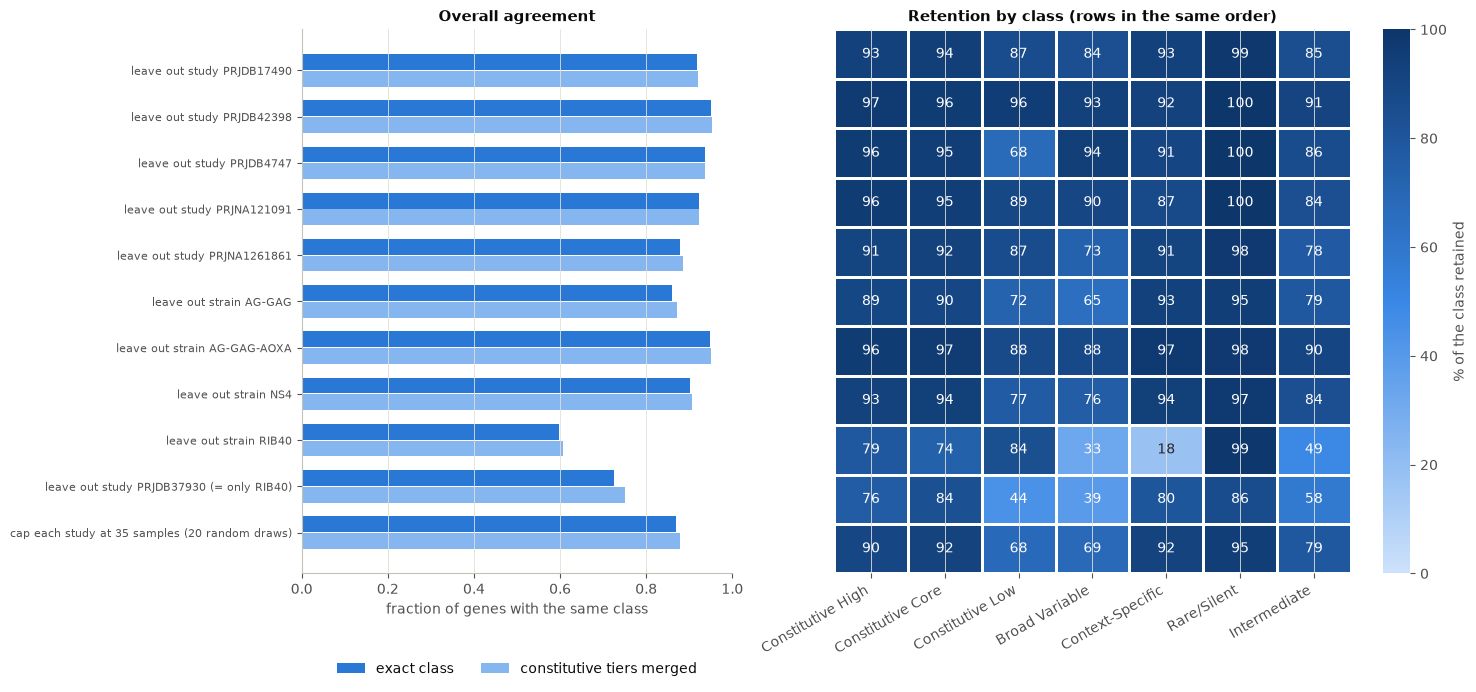

In [15]:
base_classes = classes

def run_classes(cols):
    return assign_classes(compute_gene_metrics(tpm[cols]), params)

def family(c):
    c = c.astype(str)
    return c.where(~c.str.startswith("Constitutive"), "Constitutive (any tier)")

perturbed = {}   # name -> (n samples used, [class Series, one per draw])
for study in sorted(study_of.unique()):
    cols = list(unit_meta.index[study_of != study])
    perturbed[f"leave out study {study}"] = (len(cols), [run_classes(cols)])
for strain in sorted(strain_of.unique()):
    cols = list(unit_meta.index[strain_of != strain])
    if len(cols) >= 20:
        perturbed[f"leave out strain {strain}"] = (len(cols), [run_classes(cols)])
ref_strain = strain_of.value_counts().index[0]
cols = list(unit_meta.index[strain_of == ref_strain])
twin = [name for name, (n, runs) in perturbed.items() if name.startswith("leave out study") and n == len(cols)
        and set(unit_meta.index[study_of != name.split()[-1]]) == set(cols)]
if twin:   # same sample set as an existing perturbation (e.g. the one study holding every non-reference strain): report it once
    perturbed[f"{twin[0]} (= only {ref_strain})"] = perturbed.pop(twin[0])
else:
    perturbed[f"only {ref_strain} (largest strain)"] = (len(cols), [run_classes(cols)])

cap = int(sorted(by_study.values)[-2])   # cap every study at the size of the second-largest study
draws = []
for rep in range(20):
    picks = []
    for study in study_of.unique():
        members = list(unit_meta.index[study_of == study])
        picks += list(rng.choice(members, size=min(cap, len(members)), replace=False))
    draws.append((len(picks), run_classes(picks)))
perturbed[f"cap each study at {cap} samples (20 random draws)"] = (int(np.mean([n for n, _ in draws])), [c for _, c in draws])

records, retention = [], {}
for name, (n_used, runs) in perturbed.items():
    records.append({
        "perturbation": name, "n_samples_used": n_used,
        "class_agreement": float(np.mean([class_agreement(base_classes, r) for r in runs])),
        "agreement_collapsing_constitutive_tiers": float(np.mean([class_agreement(family(base_classes), family(r)) for r in runs])),
    })
    retention[name] = pd.DataFrame(
        [{cls: float((r[base_classes == cls].astype(str) == cls).mean()) for cls in CLASS_ORDER} for r in runs]
    ).mean()
robust = pd.DataFrame(records)
retention_df = pd.DataFrame(retention).T[list(CLASS_ORDER)]
display(Markdown("**Agreement of the re-derived classes with the full-atlas classes**"))
display(robust.round(3))
display(Markdown("**Class retention: share of each class' genes that keep their class (%)**"))
display((retention_df * 100).round(0).astype(int))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 0.42 * len(robust) + 2.4), gridspec_kw={"width_ratios": [1, 1.5]})
y = np.arange(len(robust))[::-1]
ax1.barh(y + 0.18, robust["class_agreement"], height=0.34, color="#2a78d6", label="exact class")
ax1.barh(y - 0.18, robust["agreement_collapsing_constitutive_tiers"], height=0.34, color="#86b6ef", label="constitutive tiers merged")
ax1.set_yticks(y); ax1.set_yticklabels(robust["perturbation"], fontsize=8); ax1.set_xlim(0, 1)
ax1.set_xlabel("fraction of genes with the same class"); ax1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2); ax1.grid(axis="y", visible=False)
ax1.set_title("Overall agreement")
sns.heatmap(retention_df * 100, annot=True, fmt=".0f", cmap=BLUE, vmin=0, vmax=100, cbar_kws={"label": "% of the class retained"},
            linewidths=1, linecolor="white", ax=ax2, yticklabels=False)
plt.setp(ax2.get_xticklabels(), rotation=30, ha="right"); ax2.set_ylabel(""); ax2.set_title("Retention by class (rows in the same order)")
fig.tight_layout(); save_fig(fig, "rank_robustness.png"); plt.show()


In [16]:
overall = flags_table.mean()
worst = robust.sort_values("class_agreement").iloc[0]
mean_ret = retention_df.mean().sort_values()
tier_gap = float((robust["agreement_collapsing_constitutive_tiers"] - robust["class_agreement"]).mean())
display(Markdown(
    f"**Answer.** The extreme-case flags mark {overall['possible_study_effect']:.1%} of genes as `possible_study_effect`"
    f"{' and ' + format(overall['possible_strain_effect'], '.1%') + ' as `possible_strain_effect`' if multi_strain else ''}; "
    f"{overall['low_sample_support']:.1%} have `low_sample_support` and {overall['borderline_class']:.1%} are `borderline_class` "
    f"(class changes under more than a quarter of the {len(perturb_summary)} threshold perturbations). Across the {len(robust)} composition "
    f"perturbations the exact class is kept for {robust['class_agreement'].min():.0%}–{robust['class_agreement'].max():.0%} of genes; the most "
    f"disruptive is *{worst['perturbation']}* ({worst['class_agreement']:.0%}). Mean retention by class: "
    + ", ".join(f"{c} {v:.0%}" for c, v in mean_ret.items()) + ". "
    f"Part of the strain structure is **compositional**: in {skew_hi[0]} / {skew_hi[1]} the 10 most expressed genes hold "
    f"{comp_skew.loc[skew_hi, 'top10_genes_share_of_TPM']:.0%} of all TPM (median {skew_ref['top10_genes_share_of_TPM'].median():.0%} in the reference-strain studies) and "
    f"only {int(comp_skew.loc[skew_hi, 'genes_with_TPM_ge_1']):,} genes reach 1 TPM (vs {int(skew_ref['genes_with_TPM_ge_1'].median()):,}), so the TPM of most other genes is mechanically lower there."
))


**Answer.** The extreme-case flags mark 5.5% of genes as `possible_study_effect` and 4.0% as `possible_strain_effect`; 0.5% have `low_sample_support` and 6.0% are `borderline_class` (class changes under more than a quarter of the 10 threshold perturbations). Across the 11 composition perturbations the exact class is kept for 60%–95% of genes; the most disruptive is *leave out strain RIB40* (60%). Mean retention by class: Broad Variable 73%, Constitutive Low 78%, Intermediate 79%, Context-Specific 84%, Constitutive High 91%, Constitutive Core 91%, Rare/Silent 97%. Part of the strain structure is **compositional**: in PRJDB37930 / AG-GAG the 10 most expressed genes hold 18% of all TPM (median 10% in the reference-strain studies) and only 8,016 genes reach 1 TPM (vs 9,023), so the TPM of most other genes is mechanically lower there.

In [17]:
display(Markdown(
    f"**Conclusion.** The atlas is strongly organized by strain and study (see the structure statistic above), so no per-gene flag can capture all of it: "
    f"the robustness analysis is the honest summary. Class membership is **{'largely' if robust['class_agreement'].median() >= 0.85 else 'only partly'} stable** "
    f"(median agreement {robust['class_agreement'].median():.0%}); the most robust class is **{mean_ret.index[-1]}** ({mean_ret.iloc[-1]:.0%} retained) and the most "
    f"fragile is **{mean_ret.index[0]}** ({mean_ret.iloc[0]:.0%}). Merging the three constitutive tiers raises agreement by only {tier_gap:.1%} on average, so "
    f"{'the High/Core/Low boundaries are not the main source of instability' if tier_gap < 0.02 else 'tier boundaries contribute noticeably to instability'}; "
    f"what moves is mainly which genes fall in the quantile-defined tails once the sample composition changes, because the thresholds are re-derived from each "
    f"reduced atlas. The harshest tests are the ones that split the atlas along the reference-strain / engineered-strain divide (leaving out RIB40, or leaving out "
    f"the single study that holds every non-reference strain); genes carrying `possible_study_effect`, `possible_strain_effect` or `borderline_class` should be read as "
    f"provisional until more independent studies and strains are added. Because TPM is compositional, strains or studies whose transcriptome is dominated by a few "
    f"very highly expressed genes shift every other gene's TPM downward (table above); a composition-robust normalization is the natural next refinement, deliberately "
    f"not applied here so that the analysis stays free of per-study corrections."
))


**Conclusion.** The atlas is strongly organized by strain and study (see the structure statistic above), so no per-gene flag can capture all of it: the robustness analysis is the honest summary. Class membership is **largely stable** (median agreement 90%); the most robust class is **Rare/Silent** (97% retained) and the most fragile is **Broad Variable** (73%). Merging the three constitutive tiers raises agreement by only 0.7% on average, so the High/Core/Low boundaries are not the main source of instability; what moves is mainly which genes fall in the quantile-defined tails once the sample composition changes, because the thresholds are re-derived from each reduced atlas. The harshest tests are the ones that split the atlas along the reference-strain / engineered-strain divide (leaving out RIB40, or leaving out the single study that holds every non-reference strain); genes carrying `possible_study_effect`, `possible_strain_effect` or `borderline_class` should be read as provisional until more independent studies and strains are added. Because TPM is compositional, strains or studies whose transcriptome is dominated by a few very highly expressed genes shift every other gene's TPM downward (table above); a composition-robust normalization is the natural next refinement, deliberately not applied here so that the analysis stays free of per-study corrections.

## 10. Biological validation (after the fact)

**Question.** Do well-understood gene groups land where biology predicts? Gene sets come from direct GO annotations
(FungiDB, no ancestor propagation) plus product-description keywords — deliberately conservative, and **never used to
shape the classes**. Expectations were written down *before* running the test:

| group | expected region of the ranking |
|---|---|
| translation / ribosome, central metabolism, proteasome-ubiquitin, cytoskeleton-chromatin | Constitutive (High/Core) |
| stress response, secreted enzymes | Broad Variable or Context-Specific (condition-dependent) |
| secondary metabolism | Context-Specific or Rare/Silent |


,category,n_genes,expected classes,fraction in expected,fraction in all genes,odds_ratio,p_value,median constitutive percentile,q_value,supports expectation
0,translation_ribosome,244,Constitutive High / Constitutive Core,0.8443,0.4087,8.1419,0.0000,0.9016,0.0000,True
1,central_metabolism,81,Constitutive High / Constitutive Core,0.5062,0.4087,1.4871,0.0476,0.7642,0.0555,False
2,proteasome_ubiquitin,174,Constitutive High / Constitutive Core,0.7644,0.4087,4.7960,0.0000,0.8386,0.0000,True
3,cytoskeleton_chromatin,143,Constitutive High / Constitutive Core,0.7972,0.4087,5.7987,0.0000,0.7962,0.0000,True
4,stress_response,152,Broad Variable / Context-Specific,0.2303,0.2978,0.7024,0.9750,0.8357,0.9750,False
5,secreted_enzymes,524,Broad Variable / Context-Specific,0.3626,0.2978,1.3603,0.0007,0.4142,0.0009,True
6,secondary_metabolism,204,Context-Specific / Rare/Silent,0.6176,0.3033,3.8076,0.0000,0.2325,0.0000,True


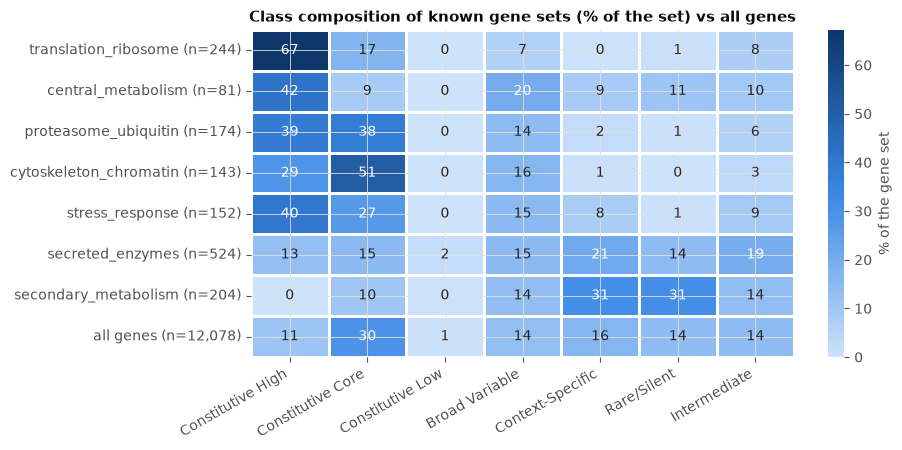

In [18]:
go = load_go_annotations(FUNGIDB_GO_GAF_FILE)
gene_sets = build_gene_sets(go, genes_tbl["description"], metrics.index)
rank_pct = 1.0 - (scores["global_expression_rank"] - 1) / len(scores)   # 1 = most constitutive
enrich = class_enrichment(classes, gene_sets, rank_pct)

expected = {
    "translation_ribosome": ["Constitutive High", "Constitutive Core"],
    "central_metabolism": ["Constitutive High", "Constitutive Core"],
    "proteasome_ubiquitin": ["Constitutive High", "Constitutive Core"],
    "cytoskeleton_chromatin": ["Constitutive High", "Constitutive Core"],
    "stress_response": ["Broad Variable", "Context-Specific"],
    "secreted_enzymes": ["Broad Variable", "Context-Specific"],
    "secondary_metabolism": ["Context-Specific", "Rare/Silent"],
}
rows = []
cls_str = classes.astype(str)
for cat, exp_classes in expected.items():
    members = gene_sets[cat].to_numpy()
    if members.sum() == 0:
        continue
    in_exp = cls_str.isin(exp_classes).to_numpy()
    a, b, c, d = int((members & in_exp).sum()), int((members & ~in_exp).sum()), int((~members & in_exp).sum()), int((~members & ~in_exp).sum())
    odds, p = spstats.fisher_exact([[a, b], [c, d]], alternative="greater")
    rows.append({
        "category": cat, "n_genes": int(members.sum()), "expected classes": " / ".join(exp_classes),
        "fraction in expected": a / members.sum(), "fraction in all genes": (a + c) / len(cls_str),
        "odds_ratio": odds, "p_value": p,
        "median constitutive percentile": float(np.median(rank_pct.to_numpy()[members])),
    })
validation = pd.DataFrame(rows)
from aoryzae_atlas.rank.diagnostics import benjamini_hochberg
validation["q_value"] = benjamini_hochberg(validation["p_value"].to_numpy())
validation["supports expectation"] = (validation["q_value"] < 0.05) & (validation["odds_ratio"] > 1)
display(validation.round(4))

comp = (enrich.pivot(index="category", columns="class", values="fraction_of_category").reindex(columns=CLASS_ORDER)
        .reindex([c for c in expected if c in set(enrich["category"])]))
n_cat = enrich.drop_duplicates("category").set_index("category")["n_category"]
background = cls_str.value_counts(normalize=True).reindex(CLASS_ORDER).fillna(0)
comp.loc["all genes"] = background.to_numpy()
comp.index = [f"{c} (n={int(n_cat[c]):,})" if c in n_cat.index else f"all genes (n={len(cls_str):,})" for c in comp.index]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
sns.heatmap(comp * 100, annot=True, fmt=".0f", cmap=BLUE, cbar_kws={"label": "% of the gene set"}, linewidths=1, linecolor="white", ax=ax)
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title("Class composition of known gene sets (% of the set) vs all genes")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout(); save_fig(fig, "rank_validation.png"); plt.show()


In [19]:
supported = validation[validation["supports expectation"]]["category"].tolist()
unsupported = validation[~validation["supports expectation"]]["category"].tolist()
bg_const = float(cls_str.str.startswith("Constitutive").mean())
def const_share(cat):
    return float(cls_str[gene_sets[cat].to_numpy()].str.startswith("Constitutive").mean())
vstat = validation.set_index("category")
display(Markdown(
    f"**Answer.** {len(supported)} of {len(validation)} pre-stated expectations are supported (odds ratio > 1, BH q < 0.05): "
    f"{', '.join(supported) if supported else 'none'}. "
    + ("Not supported: " + "; ".join(
        f"{c} (n={int(vstat.loc[c, 'n_genes'])}, odds ratio {vstat.loc[c, 'odds_ratio']:.2f}, q={vstat.loc[c, 'q_value']:.2g}; "
        f"{const_share(c):.0%} of its genes are Constitutive vs {bg_const:.0%} overall)" for c in unsupported) + ". " if unsupported else "")
    + f"The ribosome/translation set sits at a median constitutive percentile of {vstat.loc['translation_ribosome', 'median constitutive percentile']:.2f} (1 = most constitutive)."
))


**Answer.** 5 of 7 pre-stated expectations are supported (odds ratio > 1, BH q < 0.05): translation_ribosome, proteasome_ubiquitin, cytoskeleton_chromatin, secreted_enzymes, secondary_metabolism. Not supported: central_metabolism (n=81, odds ratio 1.49, q=0.056; 51% of its genes are Constitutive vs 42% overall); stress_response (n=152, odds ratio 0.70, q=0.97; 67% of its genes are Constitutive vs 42% overall). The ribosome/translation set sits at a median constitutive percentile of 0.90 (1 = most constitutive).

**Conclusion.** Where the pre-stated expectations hold (listed above), the classes capture real biology without
ever using those genes to build them: housekeeping-type sets sit at the constitutive end of the ranking and
condition-dependent sets (secreted enzymes, secondary metabolism) are enriched at the variable / specific / silent
end. Expectations that fail are findings to inspect, not reasons to retune the thresholds. The most common
reason is that a gene set is **heterogeneous** — e.g. a stress-response GO term mixes constitutively expressed
chaperones and protein-folding factors with genuinely inducible genes, so its members land in the constitutive
classes; a narrower inducible-stress set would be needed to test the hypothesis. The other reasons are sparse
annotation (small sets) and the conservative design (direct GO terms only, no ancestor propagation), so a missing
enrichment in a small set is weak evidence, whereas the strong enrichments are robust to that conservatism.


## 11. The per-gene output table

**Question.** Can everything above be delivered as one per-gene table — metrics, four scores, class, global
rank, study dominance and quality flags — in both parquet and gzipped TSV, with the thresholds that produced it
saved next to it?


In [20]:
final = assemble_rank_table(metrics, scores, classes, tiers, class_stab, study_dom, strain_dom, quality_flags, genes_tbl)
spec_cols = SPEC_COLUMNS
final.reset_index().to_parquet(EXPRESSION_RANK_FILE, index=False)
final.reset_index().to_csv(EXPRESSION_RANK_TSV_FILE, sep="\t", index=False, compression="gzip")

check = pd.read_parquet(EXPRESSION_RANK_FILE)
print(f"{len(check):,} genes x {check.shape[1]} columns -> {EXPRESSION_RANK_FILE.name}, {EXPRESSION_RANK_TSV_FILE.name}")
print(f"thresholds -> {EXPRESSION_RANK_THRESHOLDS_FILE.name}")
missing = [c for c in spec_cols + ["gene_id"] if c not in check.columns]
display(Markdown(
    f"**Answer.** Wrote **{len(check):,} genes × {check.shape[1]} columns** (all {len(spec_cols) + 1} required columns present"
    f"{'' if not missing else ' EXCEPT ' + ', '.join(missing)}); `quality_flags` is non-empty for "
    f"{(check['quality_flags'] != '').mean():.0%} of genes. The 12 reference genes with zero quantified reads in every run have no rows in "
    f"`gene_expression` at all and are not classified (not quantifiable is not the same as silent)."
))
check[["gene_id", "gene_symbol", "expression_class", "global_expression_rank", "median_TPM", "prevalence_TPM_1", "MAD_logTPM", "Tau", "quality_flags"]].head(8)


12,078 genes x 44 columns -> gene_expression_rank.parquet, gene_expression_rank.tsv.gz
thresholds -> gene_expression_rank_thresholds.tsv


**Answer.** Wrote **12,078 genes × 44 columns** (all 24 required columns present); `quality_flags` is non-empty for 16% of genes. The 12 reference genes with zero quantified reads in every run have no rows in `gene_expression` at all and are not classified (not quantifiable is not the same as silent).

,gene_id,gene_symbol,expression_class,global_expression_rank,median_TPM,prevalence_TPM_1,MAD_logTPM,Tau,quality_flags
0,AO090001000001,,Rare/Silent,11624,0.000000,0.000000,0.000000,0.979557,
1,AO090001000002,,Rare/Silent,11693,0.000000,0.000000,0.000000,0.974136,
2,AO090001000003,,Rare/Silent,11675,0.000000,0.000000,0.000000,0.920296,
3,AO090001000006,,Rare/Silent,10570,0.000000,0.013245,0.000000,0.905275,
4,AO090001000007,,Rare/Silent,9877,0.082778,0.013245,0.114737,0.846947,
5,AO090001000008,,Rare/Silent,9789,0.096969,0.039735,0.133523,0.848505,
6,AO090001000009,,Broad Variable,8419,2.362264,0.788079,0.861057,0.579699,
7,AO090001000010,,Rare/Silent,10137,0.038191,0.086093,0.054072,0.933041,


**Consistency check.** The same table is produced, end to end, by `aoryzae_atlas.rank.pipeline.build_expression_rank`
— the function behind `atlas rank genes` / `atlas refresh` and the web export. The cell below re-runs it and
**fails if this notebook's table differs**, so a change to the pipeline can never leave the notebook (or the
reverse) silently out of date.


In [21]:
reference = build_expression_rank(con, params, with_robustness=False).final
shared = [c for c in reference.columns if c in final.columns]
pd.testing.assert_frame_equal(final[shared].sort_index(), reference[shared].sort_index(), check_dtype=False, check_categorical=False)
display(Markdown(
    f"**Consistency check passed:** the notebook's per-gene table is identical to the production pipeline "
    f"(`rank.pipeline` v{__import__('aoryzae_atlas.rank.pipeline', fromlist=['x']).RANK_PIPELINE_VERSION}) on {len(shared)} columns x {len(reference):,} genes."
))


**Consistency check passed:** the notebook's per-gene table is identical to the production pipeline (`rank.pipeline` v1) on 43 columns x 12,078 genes.

**Conclusion.** The table keeps every component (metrics, scores, rank columns, flags, thresholds) so downstream
users can re-order or re-threshold without re-running the analysis, and the classes can be regenerated from the
saved thresholds. It is the same table that `atlas rank genes` writes (and `atlas refresh` re-runs whenever data
are added) and that the homepage and gene panel read through `expression_rank.json`; it lives in files
*separate* from the older condition-level classification (`gene_expression_behavior.parquet`), which the site
keeps only as a fallback.


## 12. Written report

The Markdown report is generated from this run's own variables, so it cannot drift from the notebook.


In [22]:
def md_table(df, **kw):
    return df.to_markdown(**kw)

class_tbl = counts.rename("n_genes").to_frame()
class_tbl["percent"] = (class_tbl["n_genes"] / class_tbl["n_genes"].sum() * 100).round(1)
report = [
    "# Pan-transcriptomic gene expression rank -- A. oryzae",
    "",
    f"Generated from `notebooks/gene_expression_classification.ipynb`. Atlas scope at generation: **{tpm.shape[1]} independent biological samples** "
    f"({units['sample_id'].nunique()} runs), **{study_of.nunique()} studies**, **{strain_of.nunique()} strains**, **{tpm.shape[0]:,} genes**.",
    "",
    "## Design",
    "- Unit of analysis: the biosample (technical re-sequencing runs averaged). No per-study differential expression and no condition reconstruction; "
    "study/strain effects are quality flags and robustness checks, never exclusions.",
    "- Level and stability/specificity are separate axes; dispersion is MAD/IQR of log2(TPM+1) (CV secondary); Tau is computed on log2(TPM+1); "
    "context-specificity is statistical (Tau + peak concentration) and claims no causal condition.",
    "- Every threshold is a quantile of the atlas' own distributions (no absolute TPM cut-offs):",
    "",
    md_table(th_table, index=False),
    "",
    "## Classes",
    "",
    md_table(class_tbl),
    "",
    md_table(profile),
    "",
    f"Unsupervised check: BIC {'has no elbow up to k=' + str(int(bic.index[-1])) if bic.idxmin() == bic.index[-1] else 'is minimal at k=' + str(int(bic.idxmin()))}; "
    f"HDBSCAN finds {n_hdb} dense cluster(s) ({noise_hdb:.0%} noise); rule classes vs GMM-6: ARI = {ari_rules_gmm:.2f}. Gene behavior is a continuum with density "
    "concentrations, so the classes are rule-based and the continuous scores keep the gradient.",
    "",
    "## Scores and rank",
    "",
    md_table(rho_scores),
    "",
    "`global_expression_rank` orders genes by the constitutive score (geometric mean of level, stability, prevalence); the other orderings "
    "(`rank_most_expressed`, `rank_most_stable`, `rank_most_variable`, `rank_most_specific`, `rank_rarest`) are separate columns.",
    "",
    "## Heterogeneity and robustness",
    "",
    f"Flags: possible_study_effect {overall['possible_study_effect']:.1%}, possible_strain_effect {overall['possible_strain_effect']:.1%}, "
    f"low_sample_support {overall['low_sample_support']:.1%}, borderline_class {overall['borderline_class']:.1%} of genes.",
    "",
    md_table(robust.round(3), index=False),
    "",
    "Class retention under each perturbation (% of the class' genes keeping their class):",
    "",
    md_table((retention_df * 100).round(0).astype(int)),
    "",
    f"Structure of the atlas: for {structured_strain:.0%} of genes >= 80% of the highest-expression samples come from one strain and for "
    f"{structured_study:.0%} from one study, so per-gene flags only mark the extreme tail; the robustness table is the honest summary.",
    "",
    "## Biological validation (after the fact)",
    "",
    md_table(validation.round(4), index=False),
    "",
    "## Limitations",
    f"- {study_of.nunique()} studies with unequal sizes (largest = {by_study.iloc[0] / tpm.shape[1]:.0%} of samples); classes are relative to this atlas and "
    "will be re-drawn as it grows.",
    "- Study and strain are partly confounded (some strains occur in a single study).",
    "- Validation sets use direct GO annotations and product keywords only (conservative).",
    "- Context-specific = statistically concentrated expression, not a demonstrated condition-dependence.",
    "",
    "## Files",
    "- `analysis/classification/gene_expression_rank.parquet` / `.tsv.gz` -- per-gene table",
    "- `analysis/classification/gene_expression_rank_thresholds.tsv` -- derived thresholds",
    "- `matrices/tpm/gene_by_biosample_TPM.parquet` -- genes x independent biological samples",
    "- `analysis/descriptive/rank_*.png` -- figures",
]
EXPRESSION_RANK_REPORT_FILE.write_text("\n".join(report), encoding="utf-8")
print(f"Wrote {EXPRESSION_RANK_REPORT_FILE}")


Wrote D:\PanTranscriptome\reports\gene_expression_classification.md


## 13. Candidate figures for the home page

The homepage section **Global expression behavior** (`ExpressionRankSection`, fed by `expression_rank.json`) implements
four views of this table: class composition (`rank_class_counts.png`), the level × stability map
(`rank_level_vs_stability.png`), top genes with six switchable orderings, and classes by chromosome. The remaining
figures (`rank_heatmap_representatives.png`, `rank_validation.png`, `rank_robustness.png`) are methodology figures for
the paper / a methods page. Everything is driven by columns of `gene_expression_rank.parquet`.
